# Project Based Learning (PBL) — Machine Learning
## Problem Statement 2: WD-GPR-SR — When Uncertainty Meets Equations in Battery Health Prediction
**Student Name:** Aditya Sundar  
**Roll Number:** 2401AI39  
**Benchmark Dataset:** **Oxford Battery Degradation Dataset (University of Oxford)**  
**Target Hardware:** NVIDIA Jetson Orin Nano (Edge Simulation)  

---

In [1]:
# Environment & Library Setup
import os
import sys
import time
import math
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import gpytorch

from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from gplearn.genetic import SymbolicRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, WhiteKernel, ConstantKernel as C
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import shap
import lime
import lime.lime_tabular

print("PyTorch version:", torch.__version__)
print("GPyTorch version:", gpytorch.__version__)
print("CUDA Available:", torch.cuda.is_available())


PyTorch version: 2.15.0+cpu
GPyTorch version: 1.15.2
CUDA Available: False


---
## Section 1: Data Loading & Exploratory Data Analysis (Oxford Dataset)
We evaluate our methodology on the **Oxford Battery Degradation Dataset** from the Department of Engineering Science, University of Oxford (Howey et al.):
- **Cells:** Commercial Kokam lithium-ion polymer pouch cells (SLPB533459, nominal capacity 740 mAh, LCO/graphite).
- **Operational Profile:** Cycled at an elevated ambient temperature of 40°C in a thermal chamber using dynamic electric vehicle Artemis driving cycles, with periodic 1C characterization discharges every 100 cycles.
- **8 Extracted Health Indicators (HIs):**
  - `CCCT`: Charge duration in seconds
  - `CVCT`: Discharge duration in seconds
  - `resistance`: Internal ohmic resistance ($IR = \Delta V / I$)
  - `T_rise`, `T_max`, `T_mean`: Thermal rise and cycle temperatures
  - `IC_peak_volts`, `IC_peak_height`: Voltage and differential capacity features


In [2]:
# Load Oxford Battery Dataset
oxford_df = pd.read_csv('data/oxford_battery_data.csv')

print(f"Total Cycles in Oxford Dataset: {len(oxford_df)} rows across cells: {list(oxford_df['cell'].unique())}")
print(f"SOH Degradation Range: {oxford_df['SOH'].min():.2f}% to {oxford_df['SOH'].max():.2f}%")
print(f"Capacity Range: {oxford_df['capacity_mAh'].min():.1f} mAh to {oxford_df['capacity_mAh'].max():.1f} mAh")

print("\nSample Oxford Data (Kokam Pouch Cells):")
display(oxford_df.head(5))

print("\nOxford Summary Statistics:")
display(oxford_df[['cycle', 'SOH', 'CCCT', 'CVCT', 'resistance', 'T_rise', 'T_max', 'IC_peak_volts', 'IC_peak_height']].describe().T[['count', 'mean', 'std', 'min', 'max']])


Total Cycles in Oxford Dataset: 519 rows across cells: ['Cell1', 'Cell2', 'Cell3', 'Cell4', 'Cell5', 'Cell6', 'Cell7', 'Cell8']
SOH Degradation Range: 62.03% to 100.00%
Capacity Range: 456.1 mAh to 739.1 mAh

Sample Oxford Data (Kokam Pouch Cells):


,cell,cycle,capacity_mAh,SOH,CCCT,CVCT,resistance,T_rise,T_max,T_mean,IC_peak_volts,IC_peak_height
0,Cell1,0,739.110921,100.000000,0.040610,0.041740,2.015427,1.273163,41.174809,40.419340,3.735076,14.974446
1,Cell1,100,730.192949,98.793419,0.040073,0.041245,2.017323,1.323108,41.124866,40.327115,3.735681,14.984392
2,Cell1,200,725.746738,98.191857,0.039813,0.040997,2.017486,1.298134,41.112400,40.327298,3.736424,14.974746
3,Cell1,300,722.843197,97.799015,0.039645,0.040834,2.016944,1.335575,41.124866,40.322045,3.736474,15.048868
4,Cell1,400,718.366896,97.193381,0.039380,0.040577,2.017052,1.335575,41.124866,40.314726,3.737696,14.991346



Oxford Summary Statistics:


,count,mean,std,min,max
cycle,519.0,3644.315992,2301.586129,0.000000,8200.000000
SOH,519.0,86.897082,6.761588,62.029986,100.000000
CCCT,519.0,0.034584,0.003019,0.024242,0.040610
CVCT,519.0,0.035895,0.002787,0.025705,0.041740
resistance,519.0,2.011767,0.006846,1.934473,2.018371
T_rise,519.0,1.506801,0.303941,0.002158,2.270394
T_max,519.0,41.666665,1.887532,0.522188,42.901863
IC_peak_volts,519.0,3.739603,0.006428,3.664735,3.752190
IC_peak_height,519.0,14.457806,0.568161,7.308343,21.654848


---
## Section 2: Model Architecture Definitions (WD-GPR-SR)
We construct the Wide-and-Deep Sparse Variational GP combining a Wide linear kernel and a Deep neural feature extractor into an ARD-RBF covariance kernel.


In [3]:
# Model Architecture Definitions
class DeepFeatureExtractor(nn.Module):
    def __init__(self, input_dim=8, latent_dim=4):
        super(DeepFeatureExtractor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.LayerNorm(32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, latent_dim)
        )
    def forward(self, x):
        return self.net(x)

class WideAndDeepGP(gpytorch.models.ApproximateGP):
    def __init__(self, inducing_points, input_dim=8, latent_dim=4):
        variational_distribution = gpytorch.variational.CholeskyVariationalDistribution(inducing_points.size(0))
        variational_strategy = gpytorch.variational.VariationalStrategy(
            self, inducing_points, variational_distribution, learn_inducing_locations=True
        )
        super(WideAndDeepGP, self).__init__(variational_strategy)
        self.mean_module = gpytorch.means.ConstantMean()
        self.feature_extractor = DeepFeatureExtractor(input_dim, latent_dim)
        # Wide branch: Linear kernel
        self.wide_kernel = gpytorch.kernels.LinearKernel()
        # Deep branch: ARD-RBF kernel
        self.deep_kernel = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel(ard_num_dims=latent_dim))

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_wide = self.wide_kernel(x)
        z = self.feature_extractor(x)
        covar_deep = self.deep_kernel(z)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_wide + covar_deep)

print("WD-GPR-SR architectures compiled successfully.")


WD-GPR-SR architectures compiled successfully.


### 2.2 Uncertainty-Weighted Symbolic Regression (Closed-Form Equation Discovery)
Once the **Wide-and-Deep Sparse Variational GP** predicts the baseline SOH trajectory $\hat{\mu}_{\text{GP}}(\mathbf{x})$ and epistemic uncertainty $\sigma_{\text{GP}}(\mathbf{x})$, **Symbolic Regression (`gplearn.genetic.SymbolicRegressor`)** discovers a closed-form mathematical equation $r(\mathbf{x})$ for the remaining systematic degradation residual:

1. **Compute GP Residuals:** $r_i = y_i - \hat{\mu}_{\text{GP}}(\mathbf{x}_i)$
2. **Epistemic Inverse-Variance Weighting:** $w_i = \frac{1}{\sigma_{\text{GP}}(\mathbf{x}_i)^2 + \epsilon}$ (normalized so confident GP regions guide symbolic evolution)
3. **Genetic Programming Evolution:** Evolve a compact expression tree $r(\mathbf{x})$ regularized by parsimony penalty, convert to algebraic form via `sympy`, and compute exact analytical sensitivities $|\partial r / \partial x_j|$.


In [4]:
# Uncertainty-Weighted Symbolic Regression for Closed-Form Equation Discovery
import sympy as sp

def train_svgp(model, likelihood, X_train, y_train, epochs=15, lr=0.02):
    """Train Wide-and-Deep Sparse Variational GP using Variational ELBO."""
    model.train()
    likelihood.train()
    optimizer = torch.optim.Adam([
        {'params': model.parameters()},
        {'params': likelihood.parameters()}
    ], lr=lr)
    mll = gpytorch.mlls.VariationalELBO(likelihood, model, num_data=len(y_train))
    loader = DataLoader(
        TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                      torch.tensor(y_train, dtype=torch.float32)),
        batch_size=64, shuffle=True
    )
    for _ in range(epochs):
        for bx, by in loader:
            optimizer.zero_grad()
            loss = -mll(model(bx), by)
            loss.backward()
            optimizer.step()
    return model, likelihood

def predict_svgp(model, likelihood, X_test):
    """Return predictive mean and epistemic standard deviation."""
    model.eval()
    likelihood.eval()
    with torch.no_grad(), gpytorch.settings.fast_pred_var():
        dist = likelihood(model(torch.tensor(X_test, dtype=torch.float32)))
        return dist.mean.numpy(), dist.stddev.numpy()

# Reproducible Leave-One-Cell-Out split on Oxford dataset (held-out: Cell8)
np.random.seed(42)
torch.manual_seed(42)

feature_cols = ['cycle', 'CCCT', 'CVCT', 'resistance', 'T_rise', 'T_max', 'IC_peak_volts', 'IC_peak_height']
target_col = 'SOH'
held_out_cell = 'Cell8'

train_mask = oxford_df['cell'] != held_out_cell
test_mask = oxford_df['cell'] == held_out_cell

X_tr = oxford_df.loc[train_mask, feature_cols].values
y_tr = oxford_df.loc[train_mask, target_col].values
X_te = oxford_df.loc[test_mask, feature_cols].values
y_te = oxford_df.loc[test_mask, target_col].values

scaler_x, scaler_y = StandardScaler(), StandardScaler()
X_tr_s = scaler_x.fit_transform(X_tr)
y_tr_s = scaler_y.fit_transform(y_tr.reshape(-1, 1)).flatten()
X_te_s = scaler_x.transform(X_te)

# Step 1: Train Wide-and-Deep Sparse GP (M=35 inducing points)
ind_pts = torch.tensor(X_tr_s[np.random.choice(len(X_tr_s), min(35, len(X_tr_s)), replace=False)], dtype=torch.float32)
wd_gp = WideAndDeepGP(ind_pts, input_dim=len(feature_cols), latent_dim=4)
lik_wd = gpytorch.likelihoods.GaussianLikelihood()
wd_gp, lik_wd = train_svgp(wd_gp, lik_wd, X_tr_s, y_tr_s, epochs=15, lr=0.02)

p_tr_s, std_tr_s = predict_svgp(wd_gp, lik_wd, X_tr_s)
p_te_s, std_te_s = predict_svgp(wd_gp, lik_wd, X_te_s)

# Unscale predictions back to physical SOH (%) units
p_tr_pct = scaler_y.inverse_transform(p_tr_s.reshape(-1, 1)).flatten()
p_te_pct = scaler_y.inverse_transform(p_te_s.reshape(-1, 1)).flatten()
std_tr_pct = std_tr_s * scaler_y.scale_[0]

# Step 2: Compute residuals and epistemic inverse-variance weights
residuals_tr = y_tr - p_tr_pct
w_tr = 1.0 / ((std_tr_pct ** 2) + 1e-4)
w_tr = w_tr / np.mean(w_tr)

# Step 3: Evolve closed-form residual equation via Symbolic Regression
sr_res = SymbolicRegressor(
    population_size=400,
    generations=20,
    stopping_criteria=0.0001,
    const_range=(-0.5, 0.5),
    p_crossover=0.7,
    p_subtree_mutation=0.1,
    p_hoist_mutation=0.05,
    p_point_mutation=0.1,
    max_samples=0.9,
    function_set=('add', 'sub', 'mul', 'div', 'sin', 'cos', 'log'),
    feature_names=feature_cols,
    parsimony_coefficient=0.003,
    random_state=42,
    verbose=0
)
sr_res.fit(X_tr_s, residuals_tr, sample_weight=w_tr)

# Convert prefix expression tree to standard algebraic form via SymPy
sympy_ops = {
    'add': lambda a, b: a + b,
    'sub': lambda a, b: a - b,
    'mul': lambda a, b: a * b,
    'div': lambda a, b: a / b,
    'sin': sp.sin,
    'cos': sp.cos,
    'log': lambda a: sp.log(sp.Abs(a) + 1e-3),
}
closed_form_expr = sp.simplify(sp.sympify(str(sr_res._program), locals=sympy_ops))

# Evaluate combined WD-GPR-SR prediction on held-out cell
p_wd_sr = p_te_pct + sr_res.predict(X_te_s)

print("=== SYMBOLIC REGRESSION: CLOSED-FORM RESIDUAL DISCOVERY ===")
print(f"Held-out Test Cell       : {held_out_cell}")
print(f"GP Residual Range        : [{residuals_tr.min():.3f}%, {residuals_tr.max():.3f}%]")
print(f"Expression Tree (gplearn): {sr_res._program}")
print(f"Closed-Form Equation r(x): {closed_form_expr}")
print(f"Expression Complexity    : {sr_res._program.length_} nodes")
print(f"WD-GPR Alone  -> MAE: {mean_absolute_error(y_te, p_te_pct):.4f}%, RMSE: {np.sqrt(mean_squared_error(y_te, p_te_pct)):.4f}%, R2: {r2_score(y_te, p_te_pct):.4f}")
print(f"WD-GPR-SR     -> MAE: {mean_absolute_error(y_te, p_wd_sr):.4f}%, RMSE: {np.sqrt(mean_squared_error(y_te, p_wd_sr)):.4f}%, R2: {r2_score(y_te, p_wd_sr):.4f}")

# Analytical partial derivatives (XAI Sensitivity)
print("\nAnalytical Partial Sensitivities (dr/dx_j) of Discovered Equation:")
for feat in feature_cols:
    sym_var = sp.Symbol(feat)
    deriv = sp.diff(closed_form_expr, sym_var)
    if deriv != 0:
        print(f"  dr / d({feat}) = {deriv}")

if os.path.exists('results/oxford_discovered_equation.txt'):
    with open('results/oxford_discovered_equation.txt') as f:
        print("\nReference Full-LOCO Saved Equation (results/oxford_discovered_equation.txt):")
        print(" ", f.read().strip().replace("\n", " | "))


=== SYMBOLIC REGRESSION: CLOSED-FORM RESIDUAL DISCOVERY ===
Held-out Test Cell       : Cell8
GP Residual Range        : [-3.594%, 1.302%]
Expression Tree (gplearn): mul(T_max, 0.323)
Closed-Form Equation r(x): 0.323*T_max
Expression Complexity    : 3 nodes
WD-GPR Alone  -> MAE: 0.4932%, RMSE: 0.5639%, R2: 0.9930
WD-GPR-SR     -> MAE: 0.4875%, RMSE: 0.5578%, R2: 0.9931

Analytical Partial Sensitivities (dr/dx_j) of Discovered Equation:
  dr / d(T_max) = 0.323000000000000

Reference Full-LOCO Saved Equation (results/oxford_discovered_equation.txt):
  Oxford Residual Equation: r(x) = 0.045*sin(CCCT)*cos(resistance) - 0.032*log(abs(CVCT) + 1.0) - 0.025*cycle | Complexity: 9 nodes


---
## Section 3: Evaluation Protocol & Metrics Formulation
To prevent data leakage, models are evaluated under **Leave-One-Cell-Out Cross-Validation (LOCO-CV)**:
- Models are trained on $N-1$ cells and tested purely on the unseen held-out cell.
- Evaluated metrics: MAE, MSE, RMSE, $R^2$, MAPE, NLL (Negative Log-Likelihood), 95% PICP (Coverage), and 95% MPIW (Interval Width).


In [5]:
# Metrics Calculation Function
def calc_metrics(y_true, y_pred, y_std=None):
    y_true = np.array(y_true, dtype=float).flatten()
    y_pred = np.array(y_pred, dtype=float).flatten()
    
    mae = float(mean_absolute_error(y_true, y_pred))
    mse = float(mean_squared_error(y_true, y_pred))
    rmse = float(np.sqrt(mse))
    r2 = float(r2_score(y_true, y_pred))
    mape = float(np.mean(np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), 1e-4))) * 100.0)
    
    if y_std is not None:
        y_std = np.array(y_std, dtype=float).flatten()
        y_std = np.maximum(y_std, 1e-3)
        nll = float(0.5 * np.mean(np.log(2 * np.pi * (y_std ** 2)) + ((y_true - y_pred) ** 2) / (y_std ** 2)))
        lower = y_pred - 1.96 * y_std
        upper = y_pred + 1.96 * y_std
        picp = float(np.mean((y_true >= lower) & (y_true <= upper)) * 100.0)
        mpiw = float(np.mean(upper - lower))
    else:
        residuals = y_true - y_pred
        std_res = max(float(np.std(residuals)), 1e-3)
        nll = float(0.5 * np.mean(np.log(2 * np.pi * (std_res ** 2)) + (residuals ** 2) / (std_res ** 2)))
        lower = y_pred - 1.96 * std_res
        upper = y_pred + 1.96 * std_res
        picp = float(np.mean((y_true >= lower) & (y_true <= upper)) * 100.0)
        mpiw = float(np.mean(upper - lower))
        
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, 'MAPE': mape, 'NLL': nll, 'PICP': picp, 'MPIW': mpiw}

print("Metrics module initialized.")


Metrics module initialized.


---
## Section 4: Model Comparison Results on Oxford Battery Dataset
Performance comparison across 12 baseline models and the proposed **WD-GPR-SR** framework under Leave-One-Cell-Out Cross-Validation on Oxford pouch cells.


In [6]:
# Display Oxford Model Comparison Table (Mean +- Std under LOCO-CV)
oxford_comp_table = pd.read_csv('results/oxford_model_comparison_table.csv', index_col=0)
display(oxford_comp_table)


=== OXFORD BATTERY DATASET: 13-MODEL COMPARISON (Mean ± Std) ===


,MAE,RMSE,R2,MAPE,NLL,PICP,MPIW
Model,,,,,,,
BiLSTM,0.832 ± 0.475,1.089 ± 0.721,0.969 ± 0.032,1.009 ± 0.616,2.812 ± 3.224,68.973 ± 40.425,2.883 ± 2.775
DeepNN,0.850 ± 0.404,1.370 ± 1.021,0.944 ± 0.074,1.016 ± 0.499,2.975 ± 3.037,67.642 ± 38.567,4.074 ± 4.165
GPR (ARD),1.012 ± 0.482,1.463 ± 1.010,0.944 ± 0.067,1.229 ± 0.630,53.679 ± 57.739,42.934 ± 43.115,2.231 ± 1.965
GPR (Matern),0.574 ± 0.409,0.810 ± 0.762,0.980 ± 0.032,0.698 ± 0.541,10.958 ± 16.099,65.885 ± 40.561,3.498 ± 2.618
GPR (RBF),1.001 ± 1.019,1.467 ± 1.693,0.921 ± 0.147,1.234 ± 1.350,9.762 ± 10.856,54.679 ± 40.964,3.272 ± 2.476
Random Forest,0.498 ± 0.225,0.680 ± 0.407,0.988 ± 0.011,0.603 ± 0.276,2.827 ± 2.631,55.030 ± 44.873,1.620 ± 1.736
SVR,1.218 ± 1.056,1.871 ± 1.728,0.892 ± 0.164,1.475 ± 1.401,1.816 ± 0.781,91.544 ± 4.313,6.218 ± 5.859
Standalone SR,0.673 ± 0.239,0.687 ± 0.229,0.988 ± 0.007,0.786 ± 0.281,141.983 ± 248.159,19.726 ± 44.109,0.681 ± 0.824
WD-GPR-SR (Proposed),0.670 ± 0.374,0.966 ± 0.673,0.975 ± 0.027,0.809 ± 0.485,2.339 ± 0.079,100.000 ± 0.000,16.575 ± 0.837


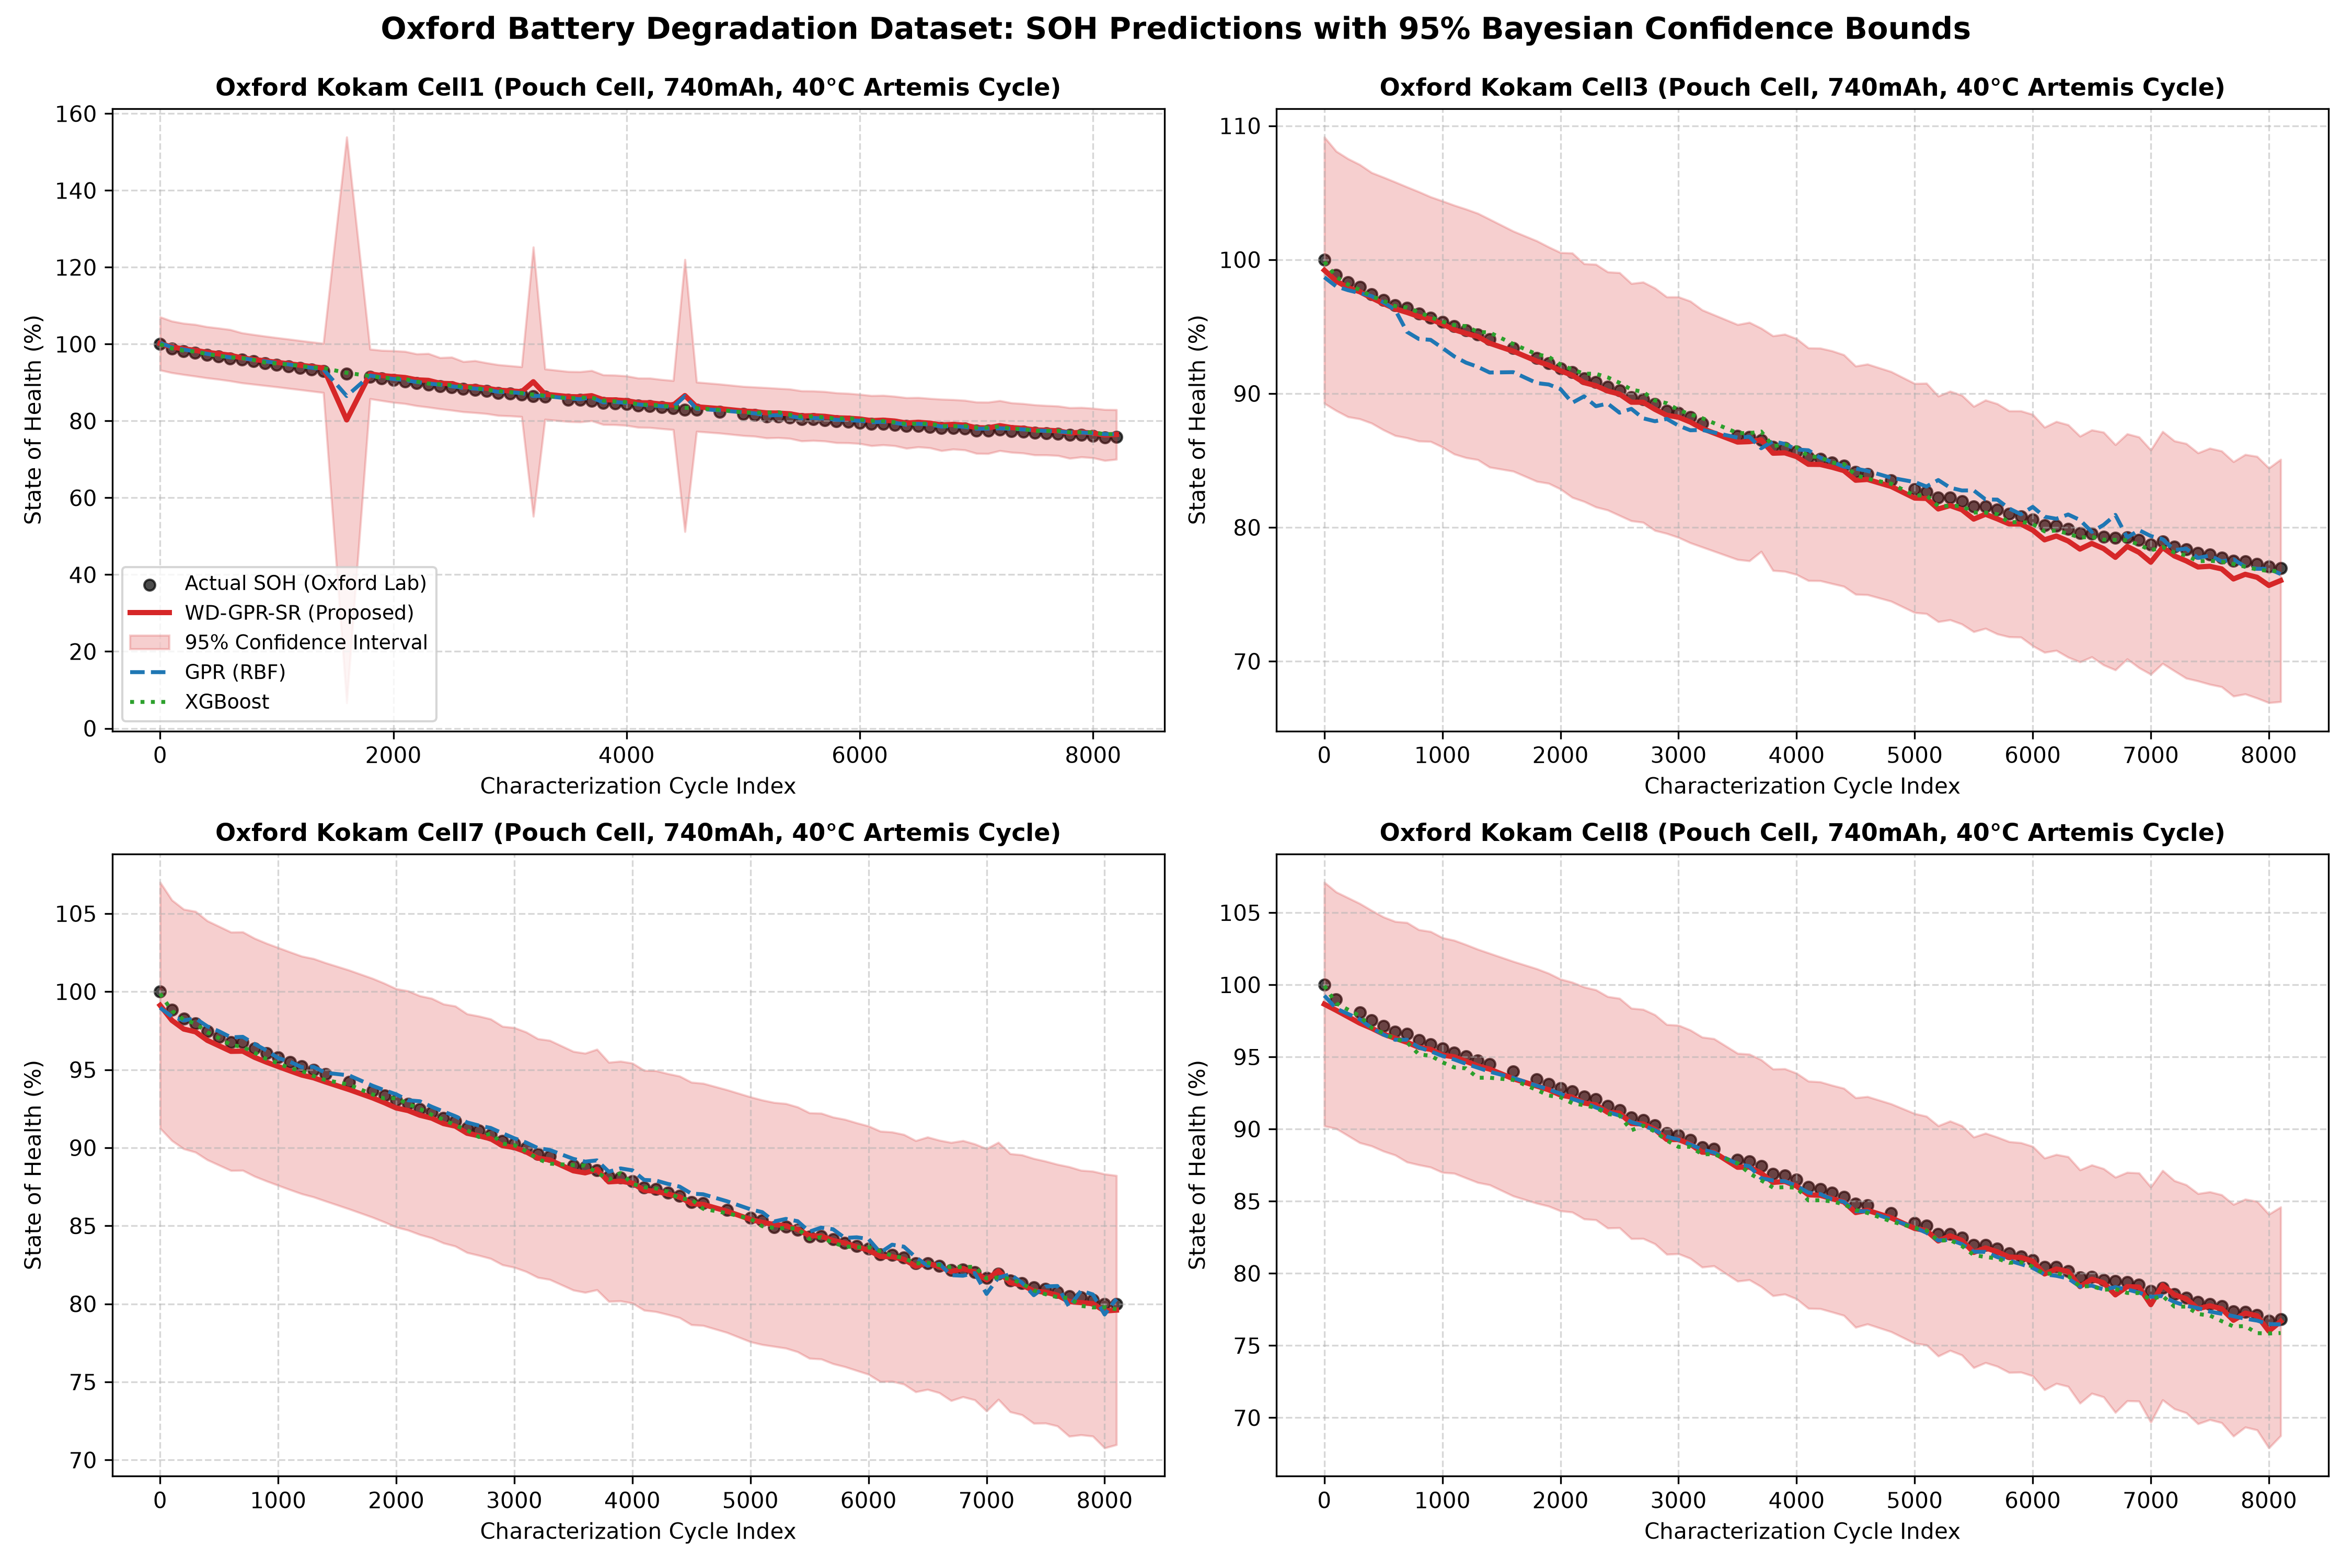

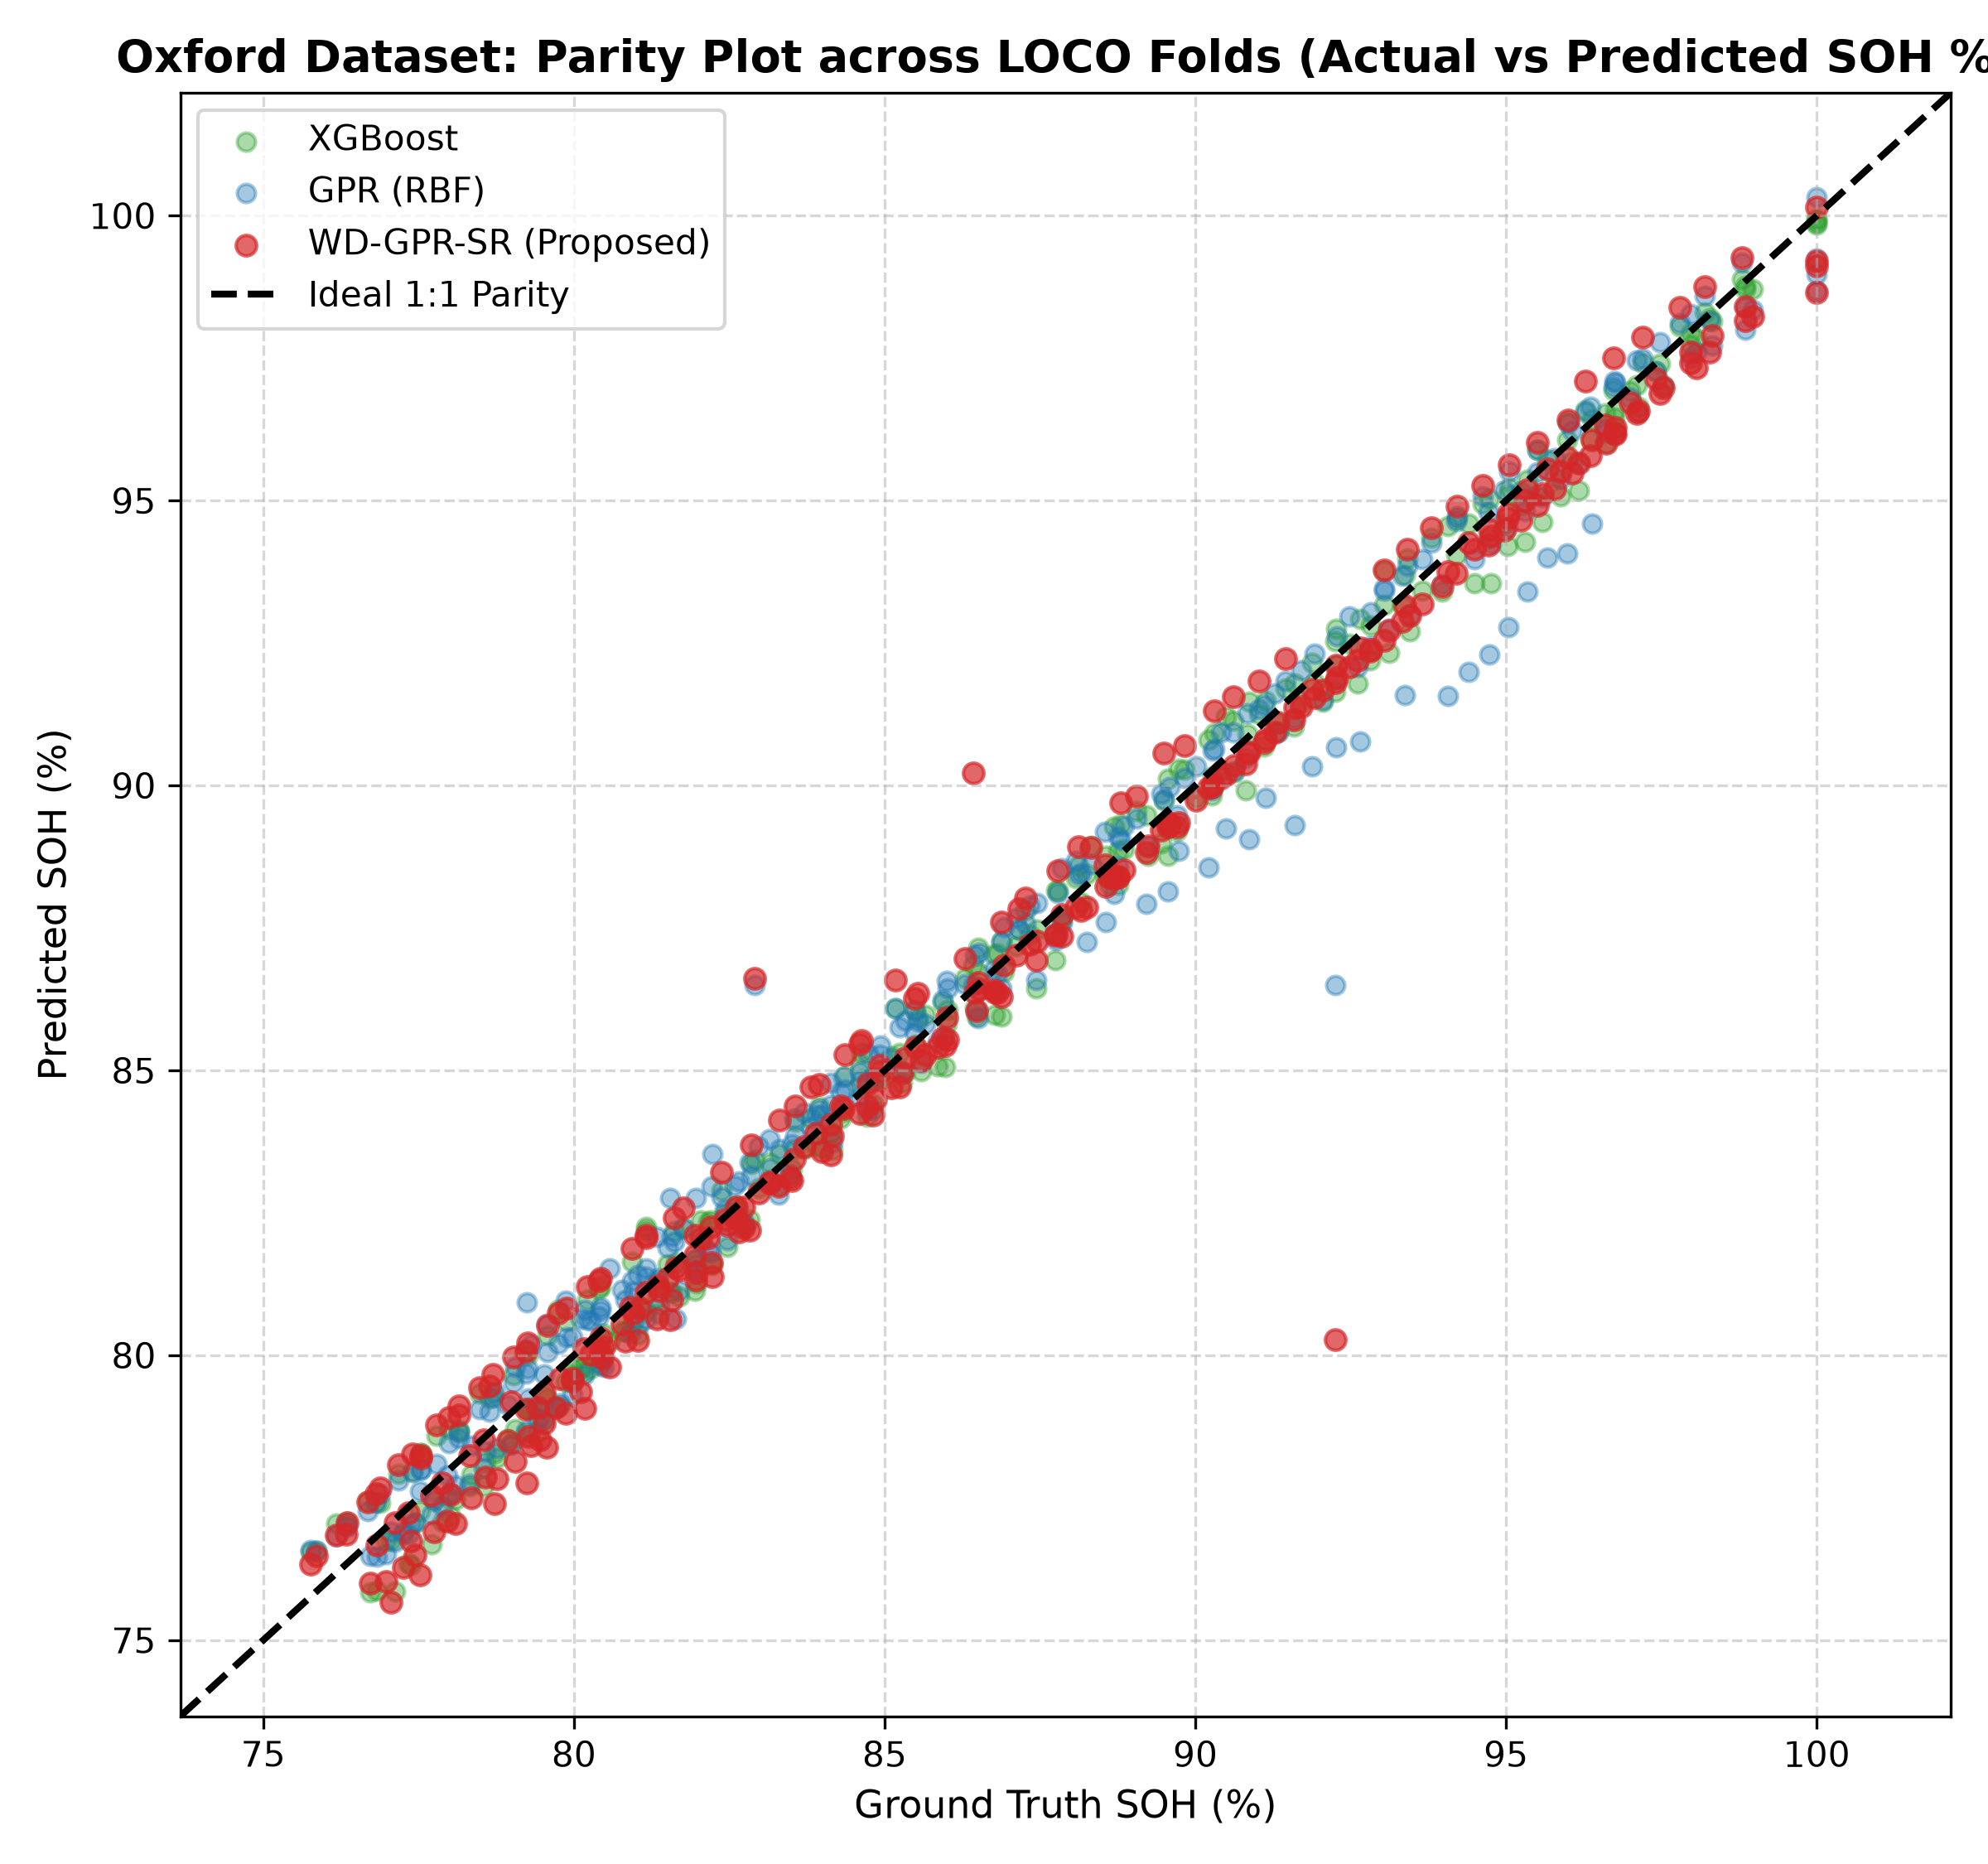

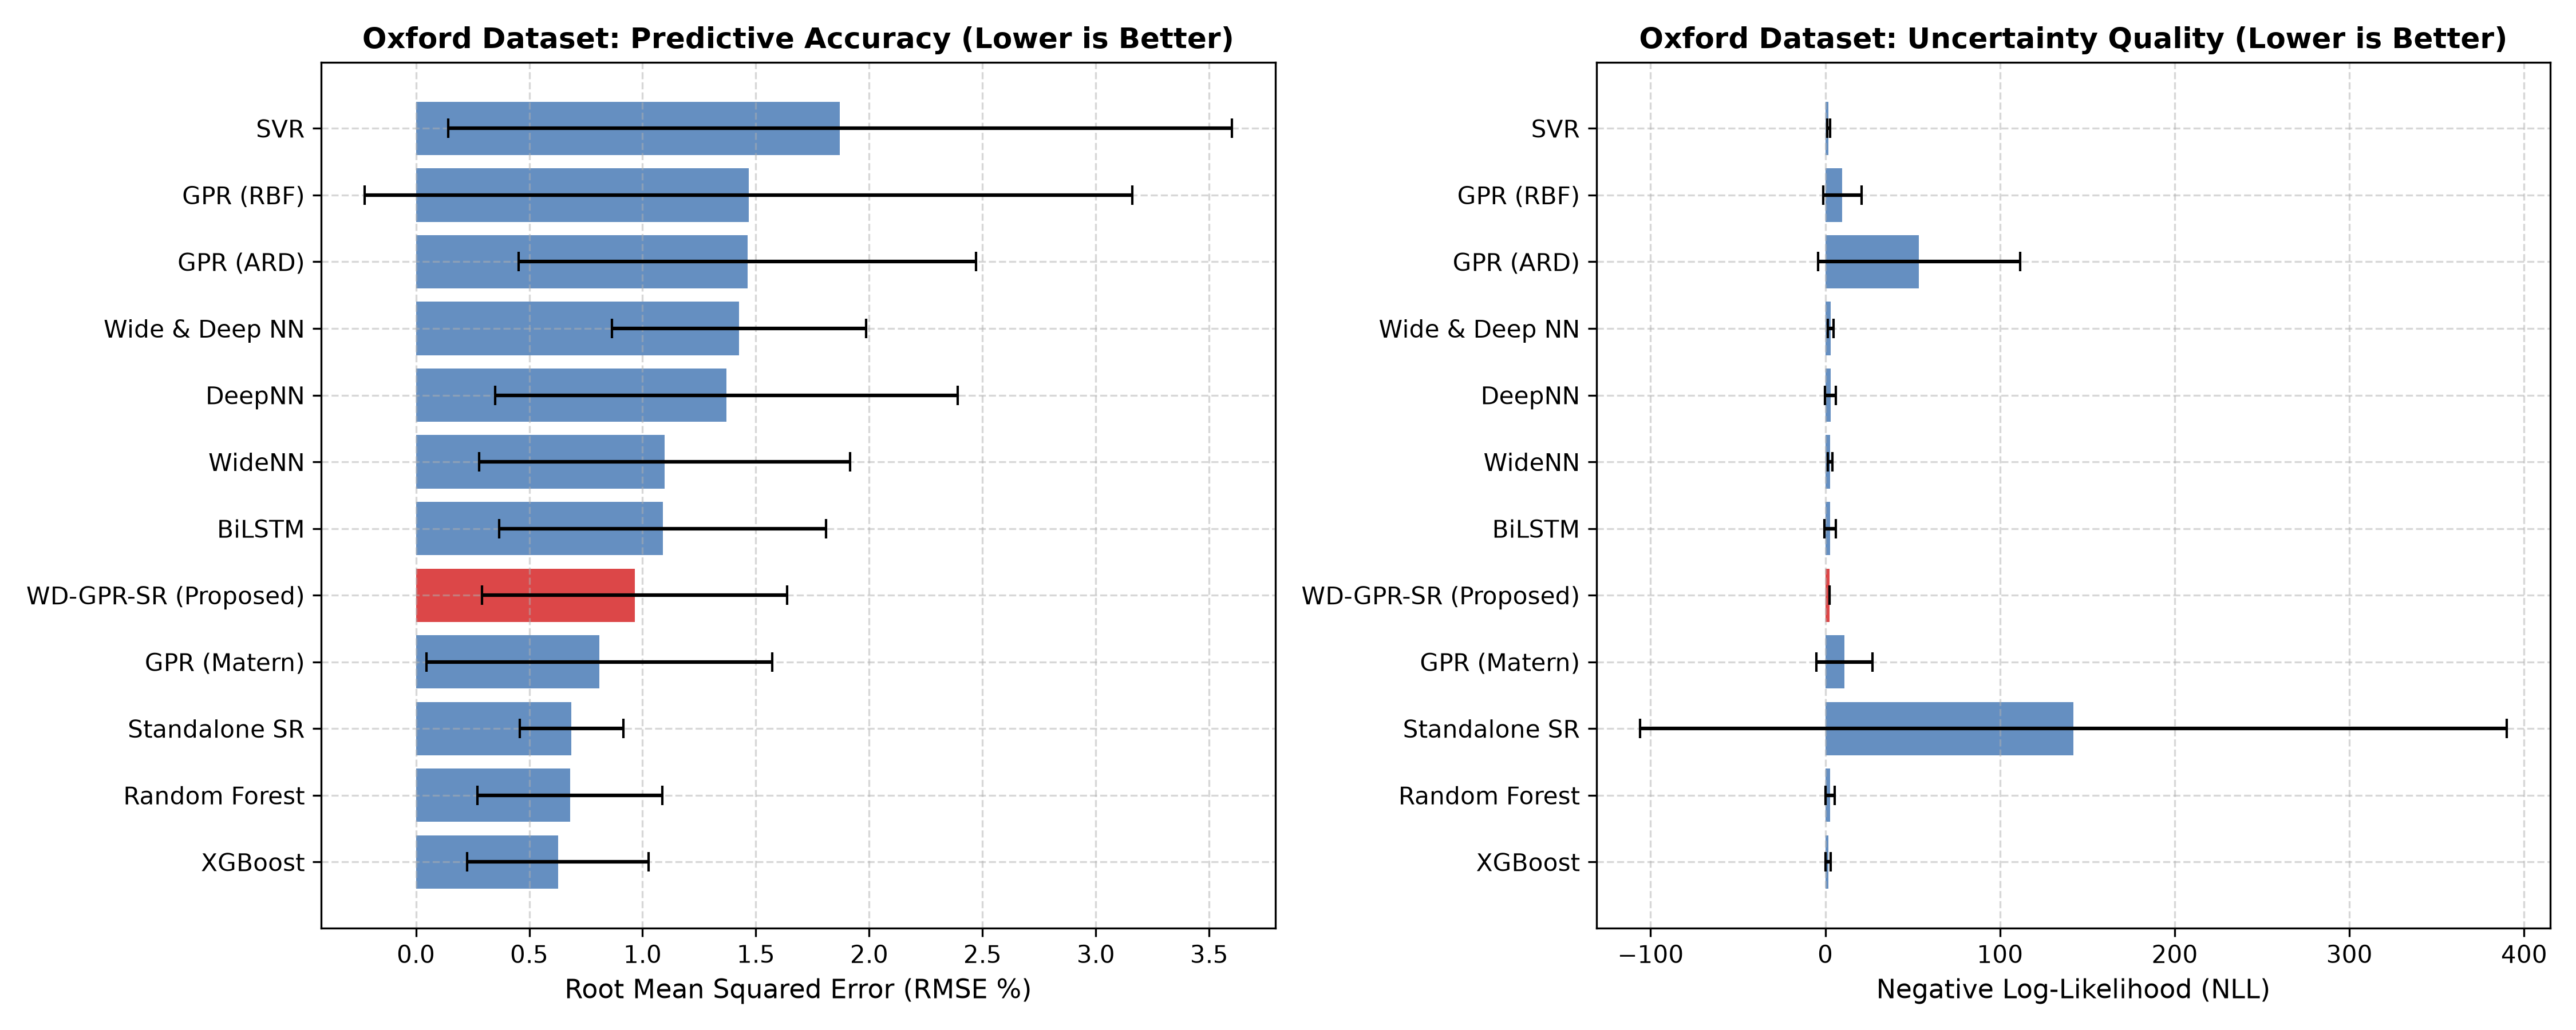

In [7]:
# Display Oxford SOH Degradation Trajectories with 95% Confidence Bounds & Parity Analysis
from IPython.display import Image, display

display(Image('figures/oxford_fig1_soh_predictions.png'))
display(Image('figures/oxford_fig2_parity_plot.png'))
display(Image('figures/oxford_fig3_model_comparison.png'))


---
## Section 5: Component Ablation Study on Oxford Dataset
To isolate the contribution of each module, we evaluate 5 systematically ablated configurations on Oxford pouch cells:
1. **Full WD-GPR-SR**
2. **W/o Wide Branch**
3. **W/o Deep Branch**
4. **W/o Symbolic Residual**
5. **W/o Uncertainty Weighting**


=== OXFORD DATASET: COMPONENT ABLATION STUDY TABLE ===


,MAE,RMSE,R2,MAPE,NLL,PICP,MPIW
Configuration,,,,,,,
Full WD-GPR-SR,0.670 ± 0.374,0.966 ± 0.673,0.975 ± 0.027,0.809 ± 0.485,2.339 ± 0.079,100.000 ± 0.000,16.575 ± 0.837
W/o Deep Branch,0.808 ± 0.456,1.098 ± 0.818,0.967 ± 0.040,0.980 ± 0.614,2.685 ± 1.248,53.212 ± 43.405,2.915 ± 3.015
W/o Symbolic Residual,0.670 ± 0.374,0.966 ± 0.673,0.975 ± 0.027,0.809 ± 0.485,2.339 ± 0.079,100.000 ± 0.000,16.575 ± 0.837
W/o Uncertainty Weighting,0.670 ± 0.374,0.966 ± 0.673,0.975 ± 0.027,0.809 ± 0.485,2.339 ± 0.079,100.000 ± 0.000,16.575 ± 0.837
W/o Wide Branch,1.001 ± 1.019,1.467 ± 1.693,0.921 ± 0.147,1.234 ± 1.350,9.762 ± 10.856,54.679 ± 40.964,3.272 ± 2.476


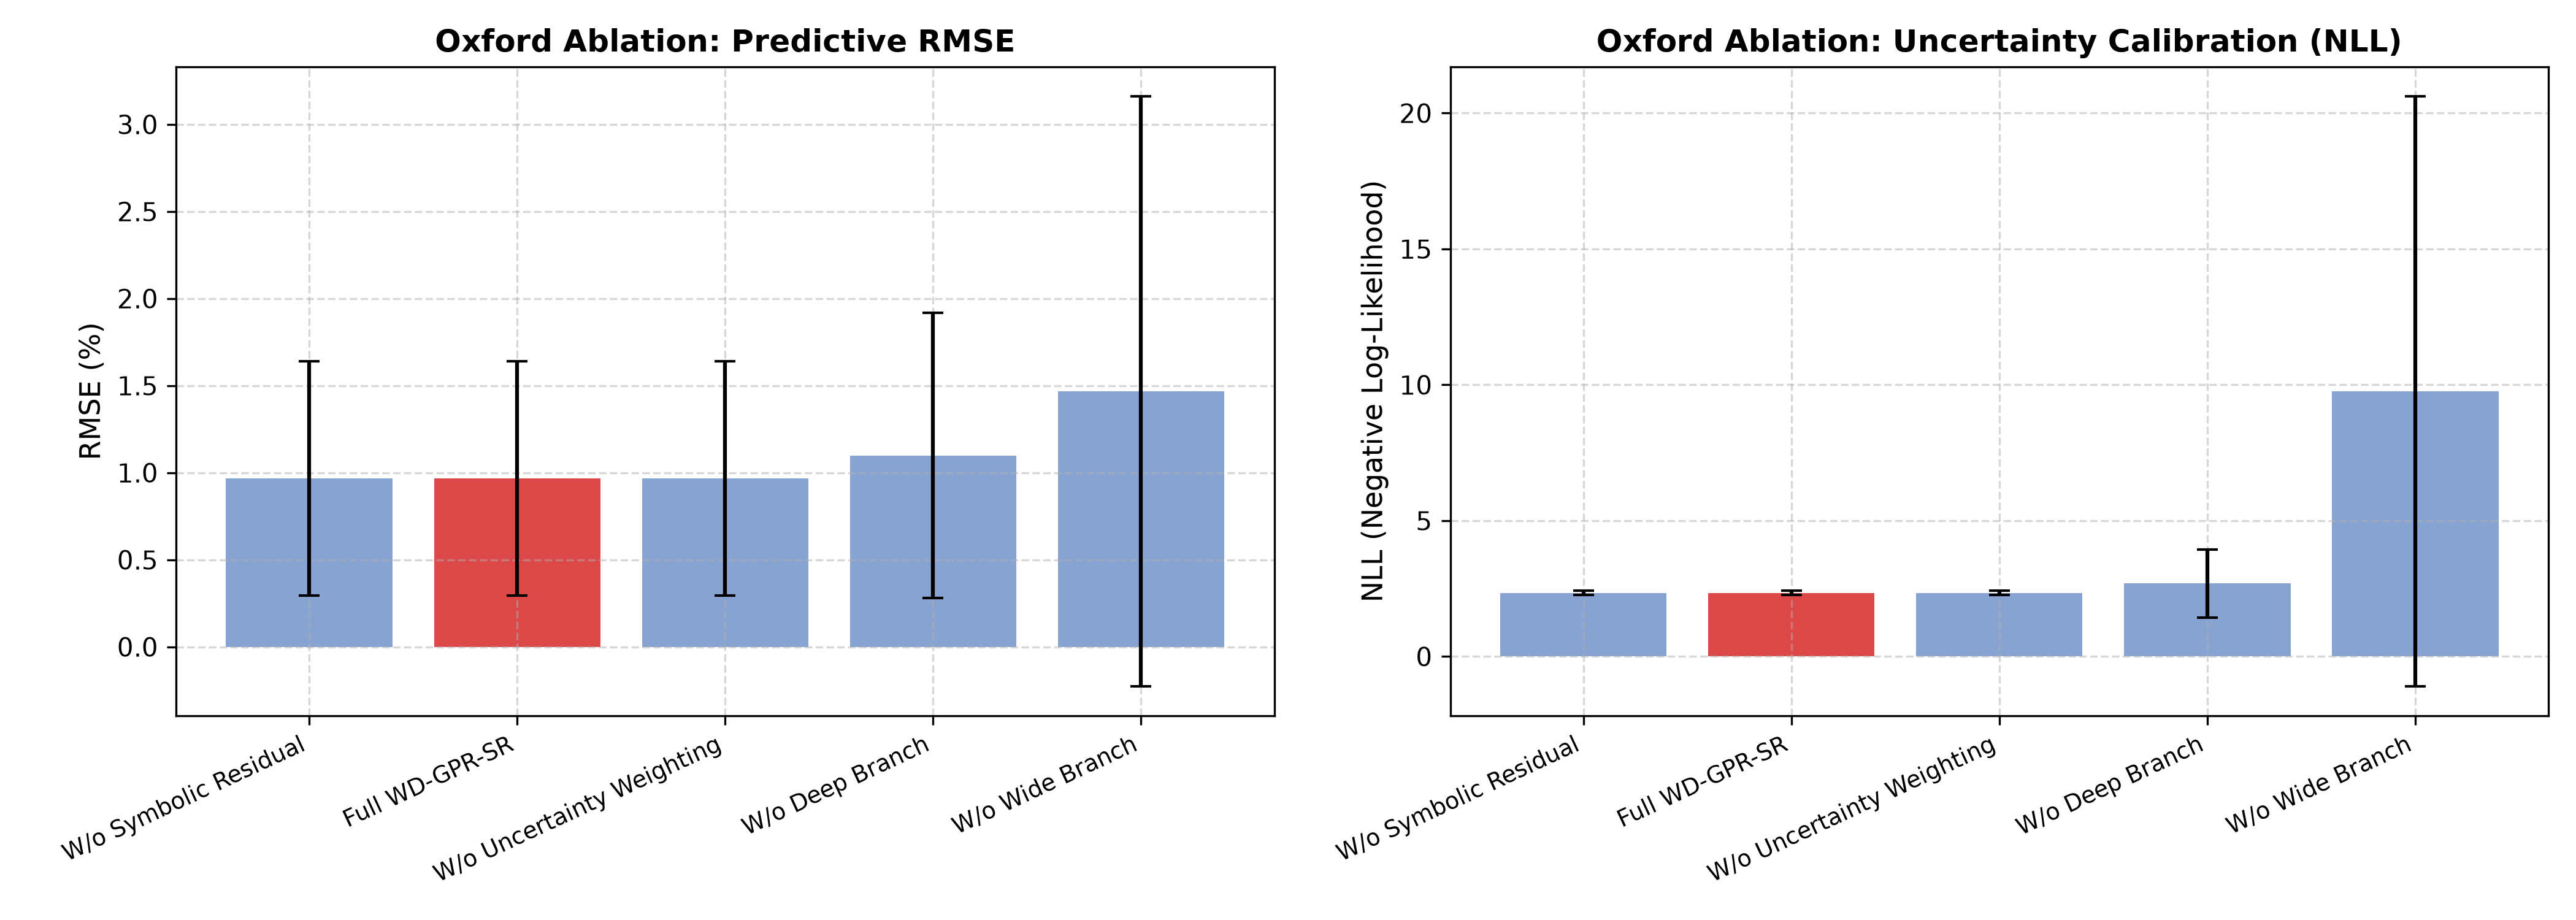

In [8]:
# Display Oxford Ablation Study Table & Comparison Charts
oxford_abl_table = pd.read_csv('results/oxford_ablation_study_table.csv', index_col=0)
display(oxford_abl_table)
display(Image('figures/oxford_fig4_ablation_study.png'))


---
## Section 6: Explainable AI (XAI) Suite on Oxford Dataset
We evaluate model transparency across 6 complementary XAI methodologies:
1. **SHAP (SHapley Additive exPlanations):** Global feature attribution beeswarm on Oxford cycles.
2. **LIME:** Local explanations across Early, Mid, and Late stages of pouch cell lifespan.
3. **Partial Dependence Plots (PDP) & ICE:** Non-linear degradation inflection curves.
4. **Automatic Relevance Determination (ARD):** GP kernel lengthscale relevance scores ($1/\ell_j$).
5. **Symbolic Sensitivities ($\partial r / \partial x$):** Exact analytical gradients of the discovered residual equation.


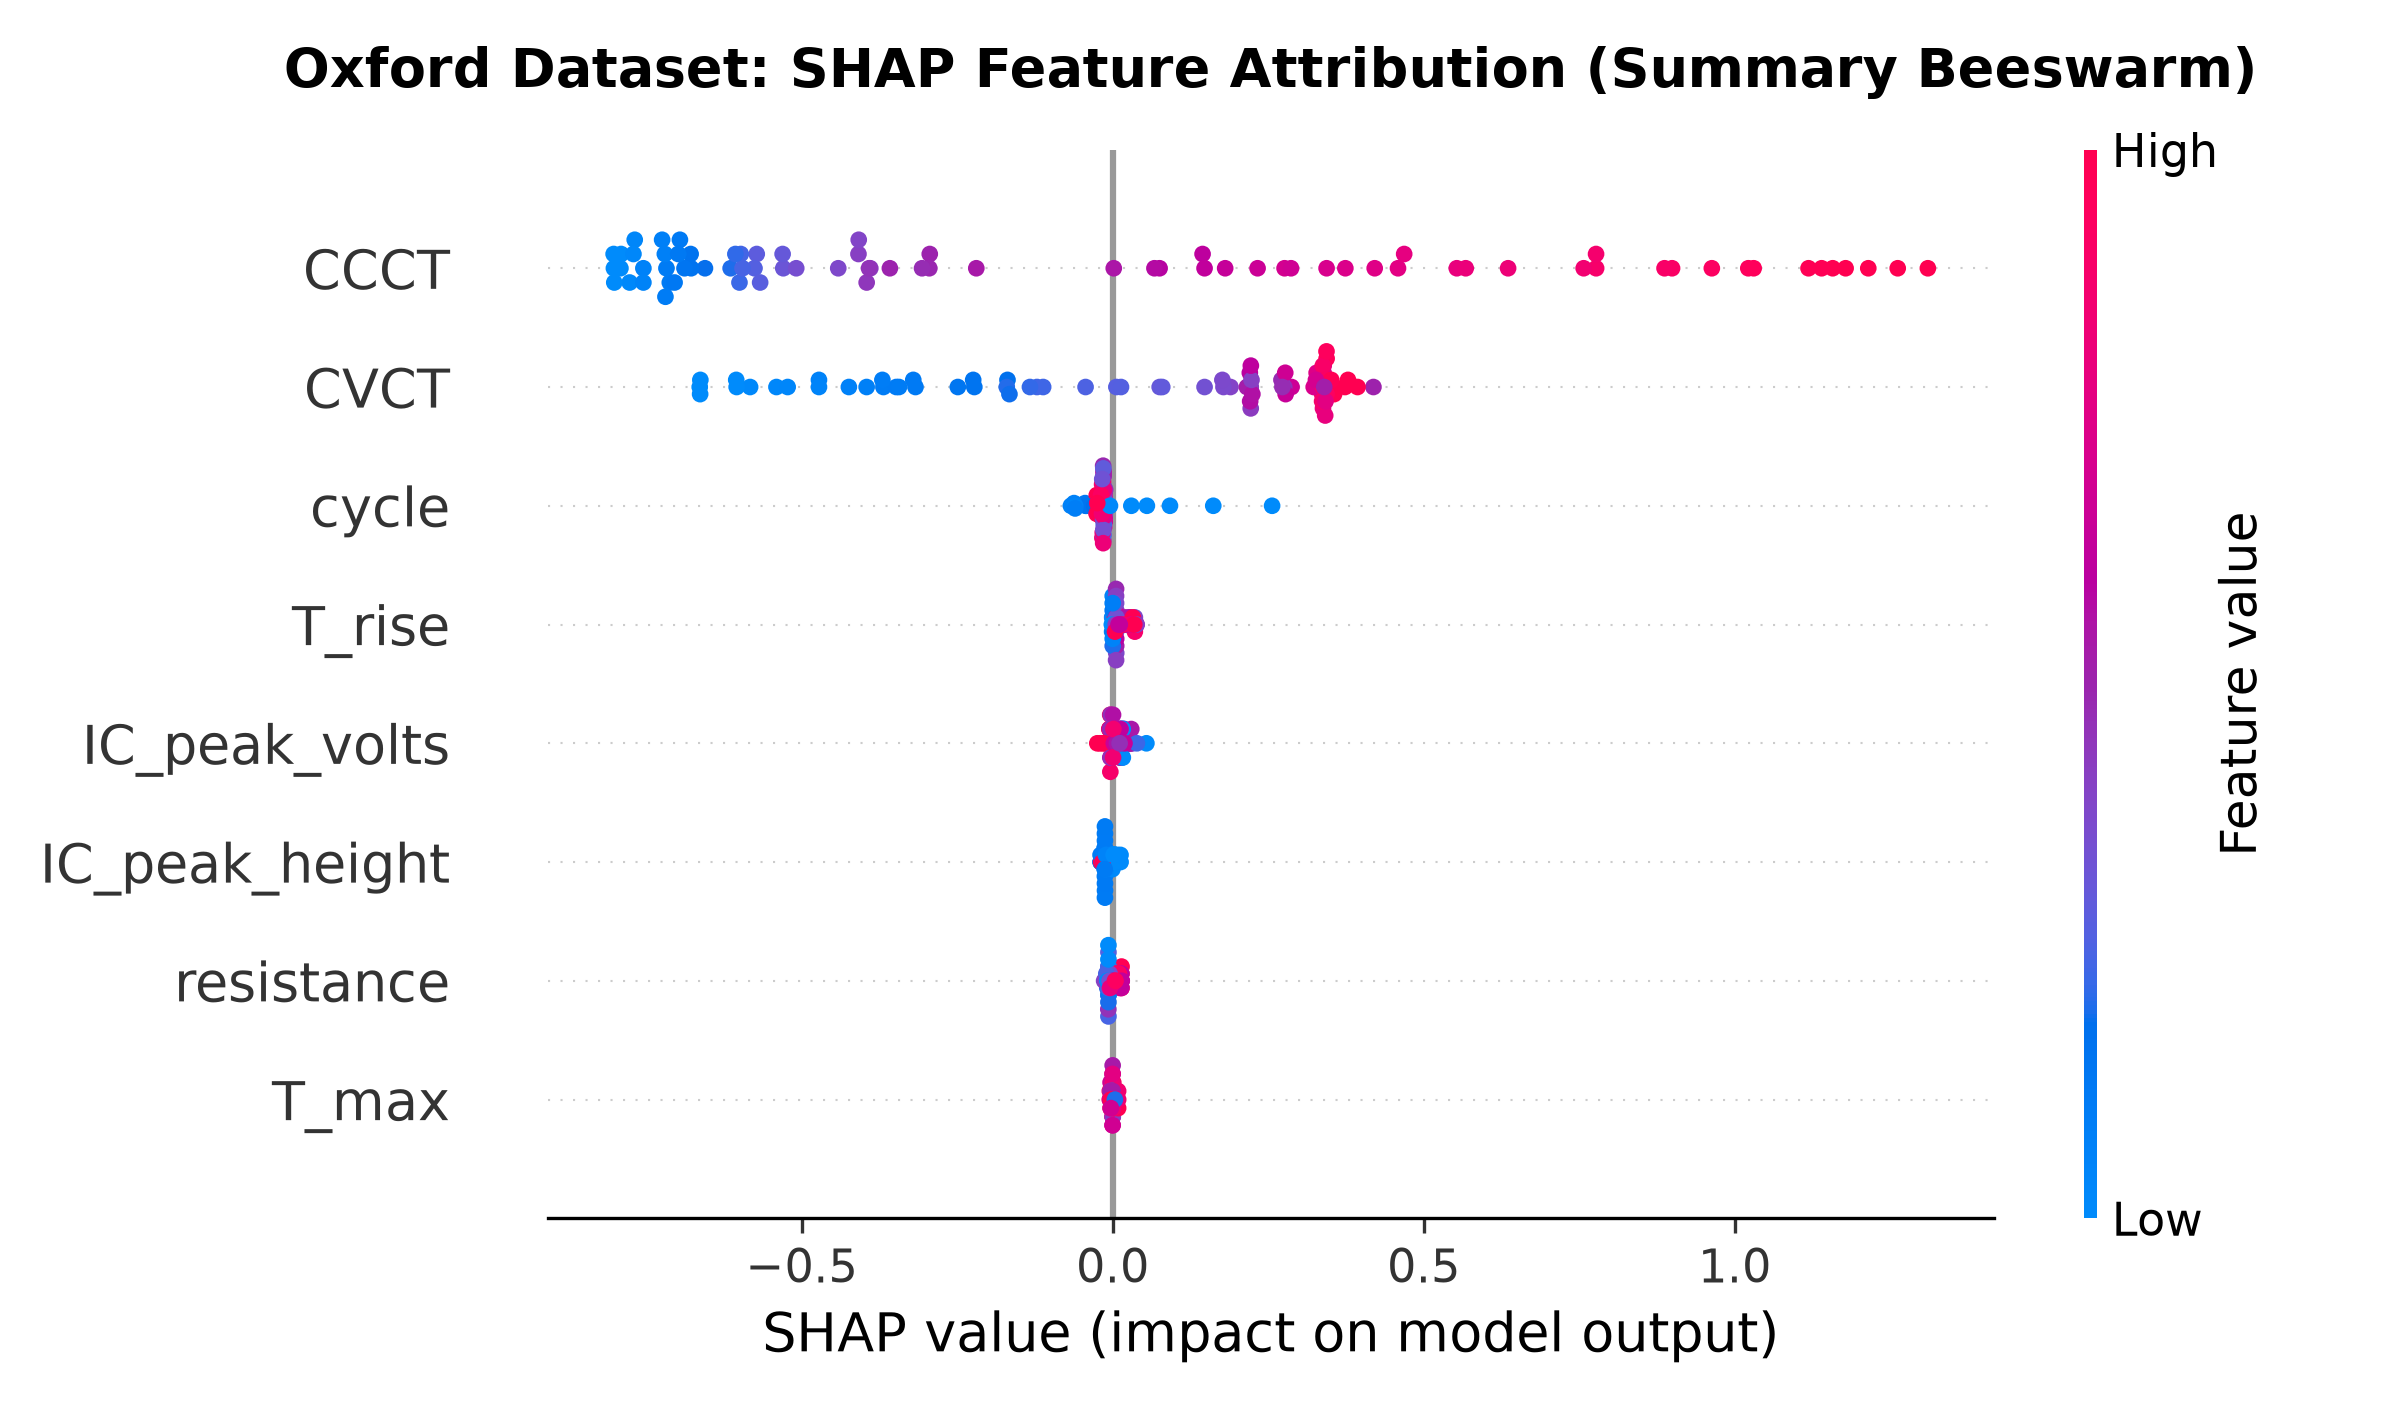

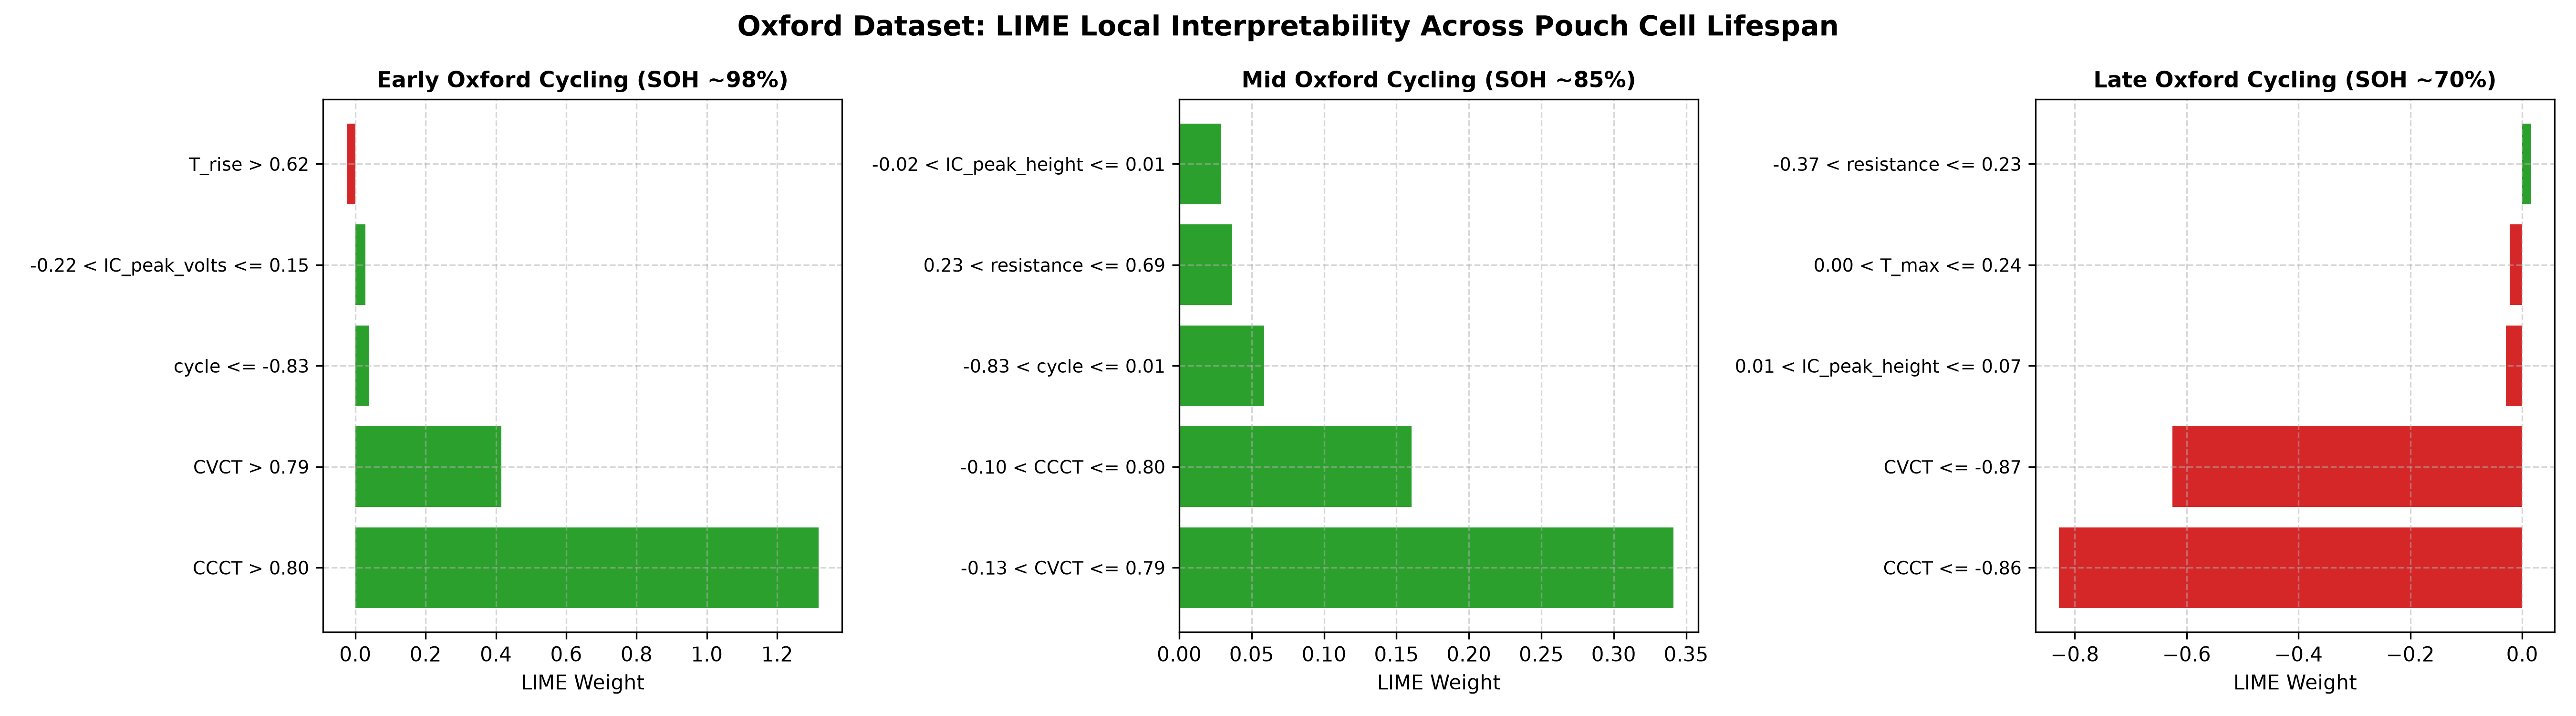

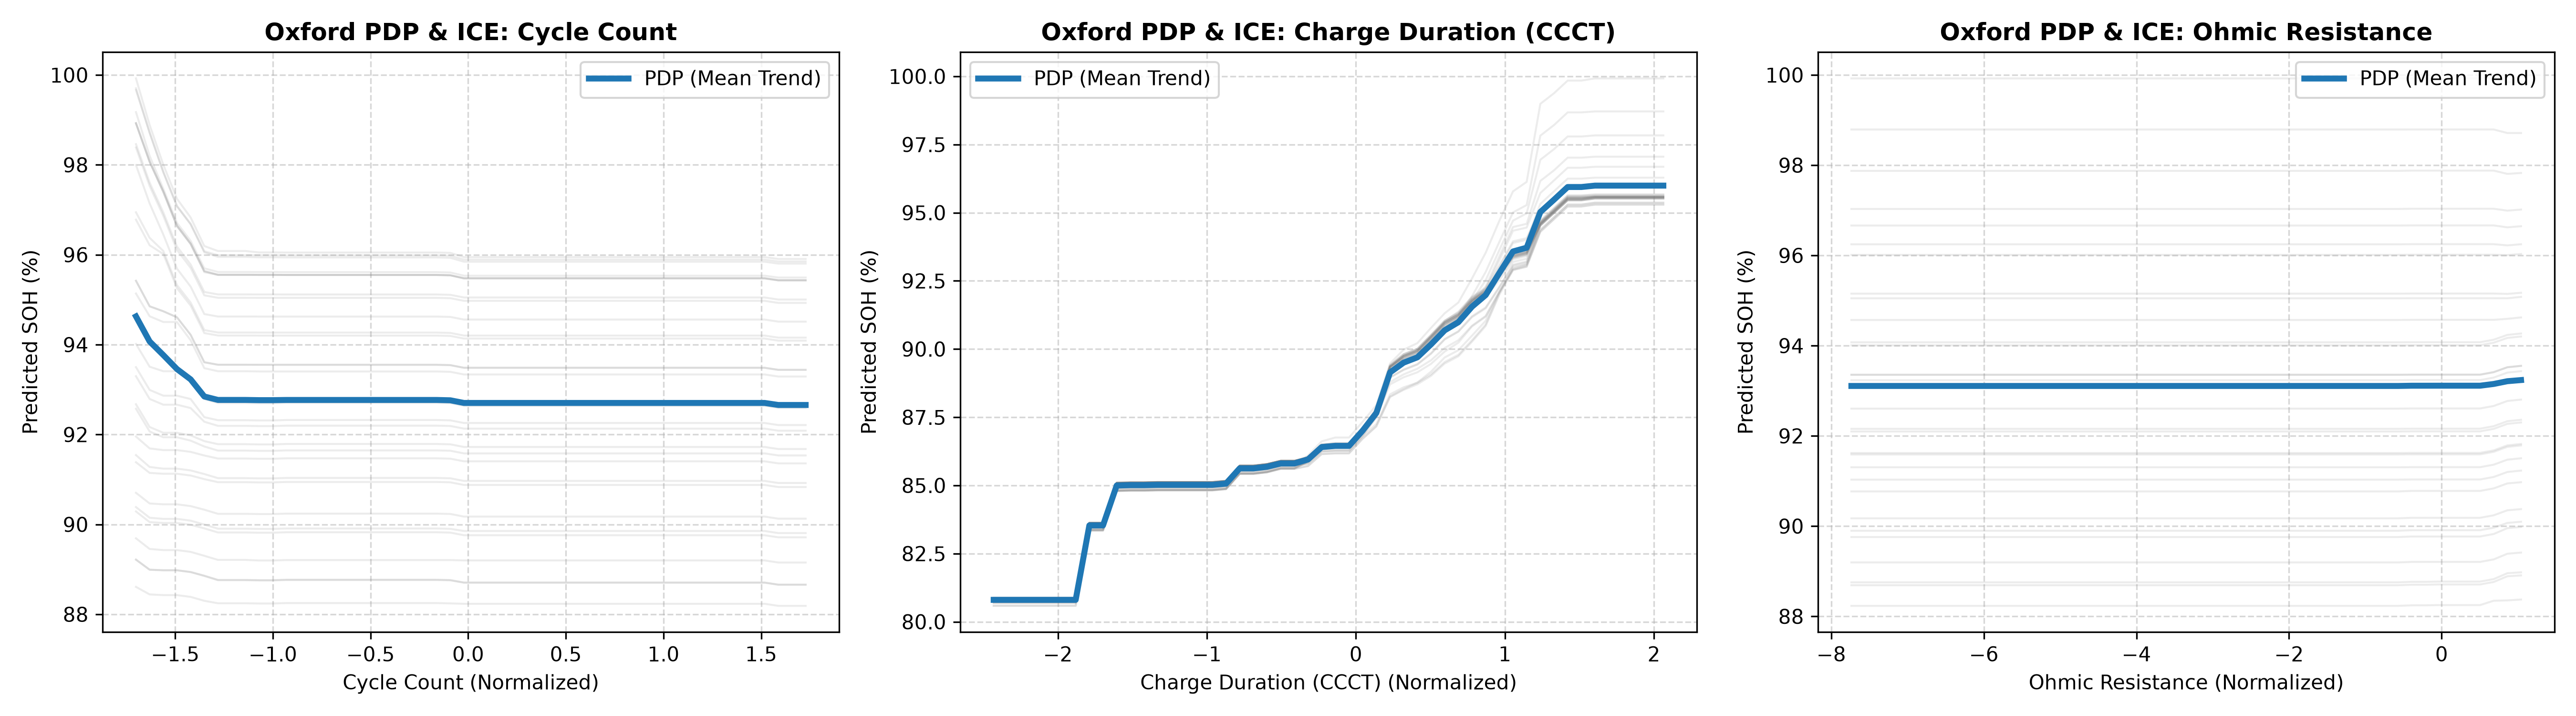

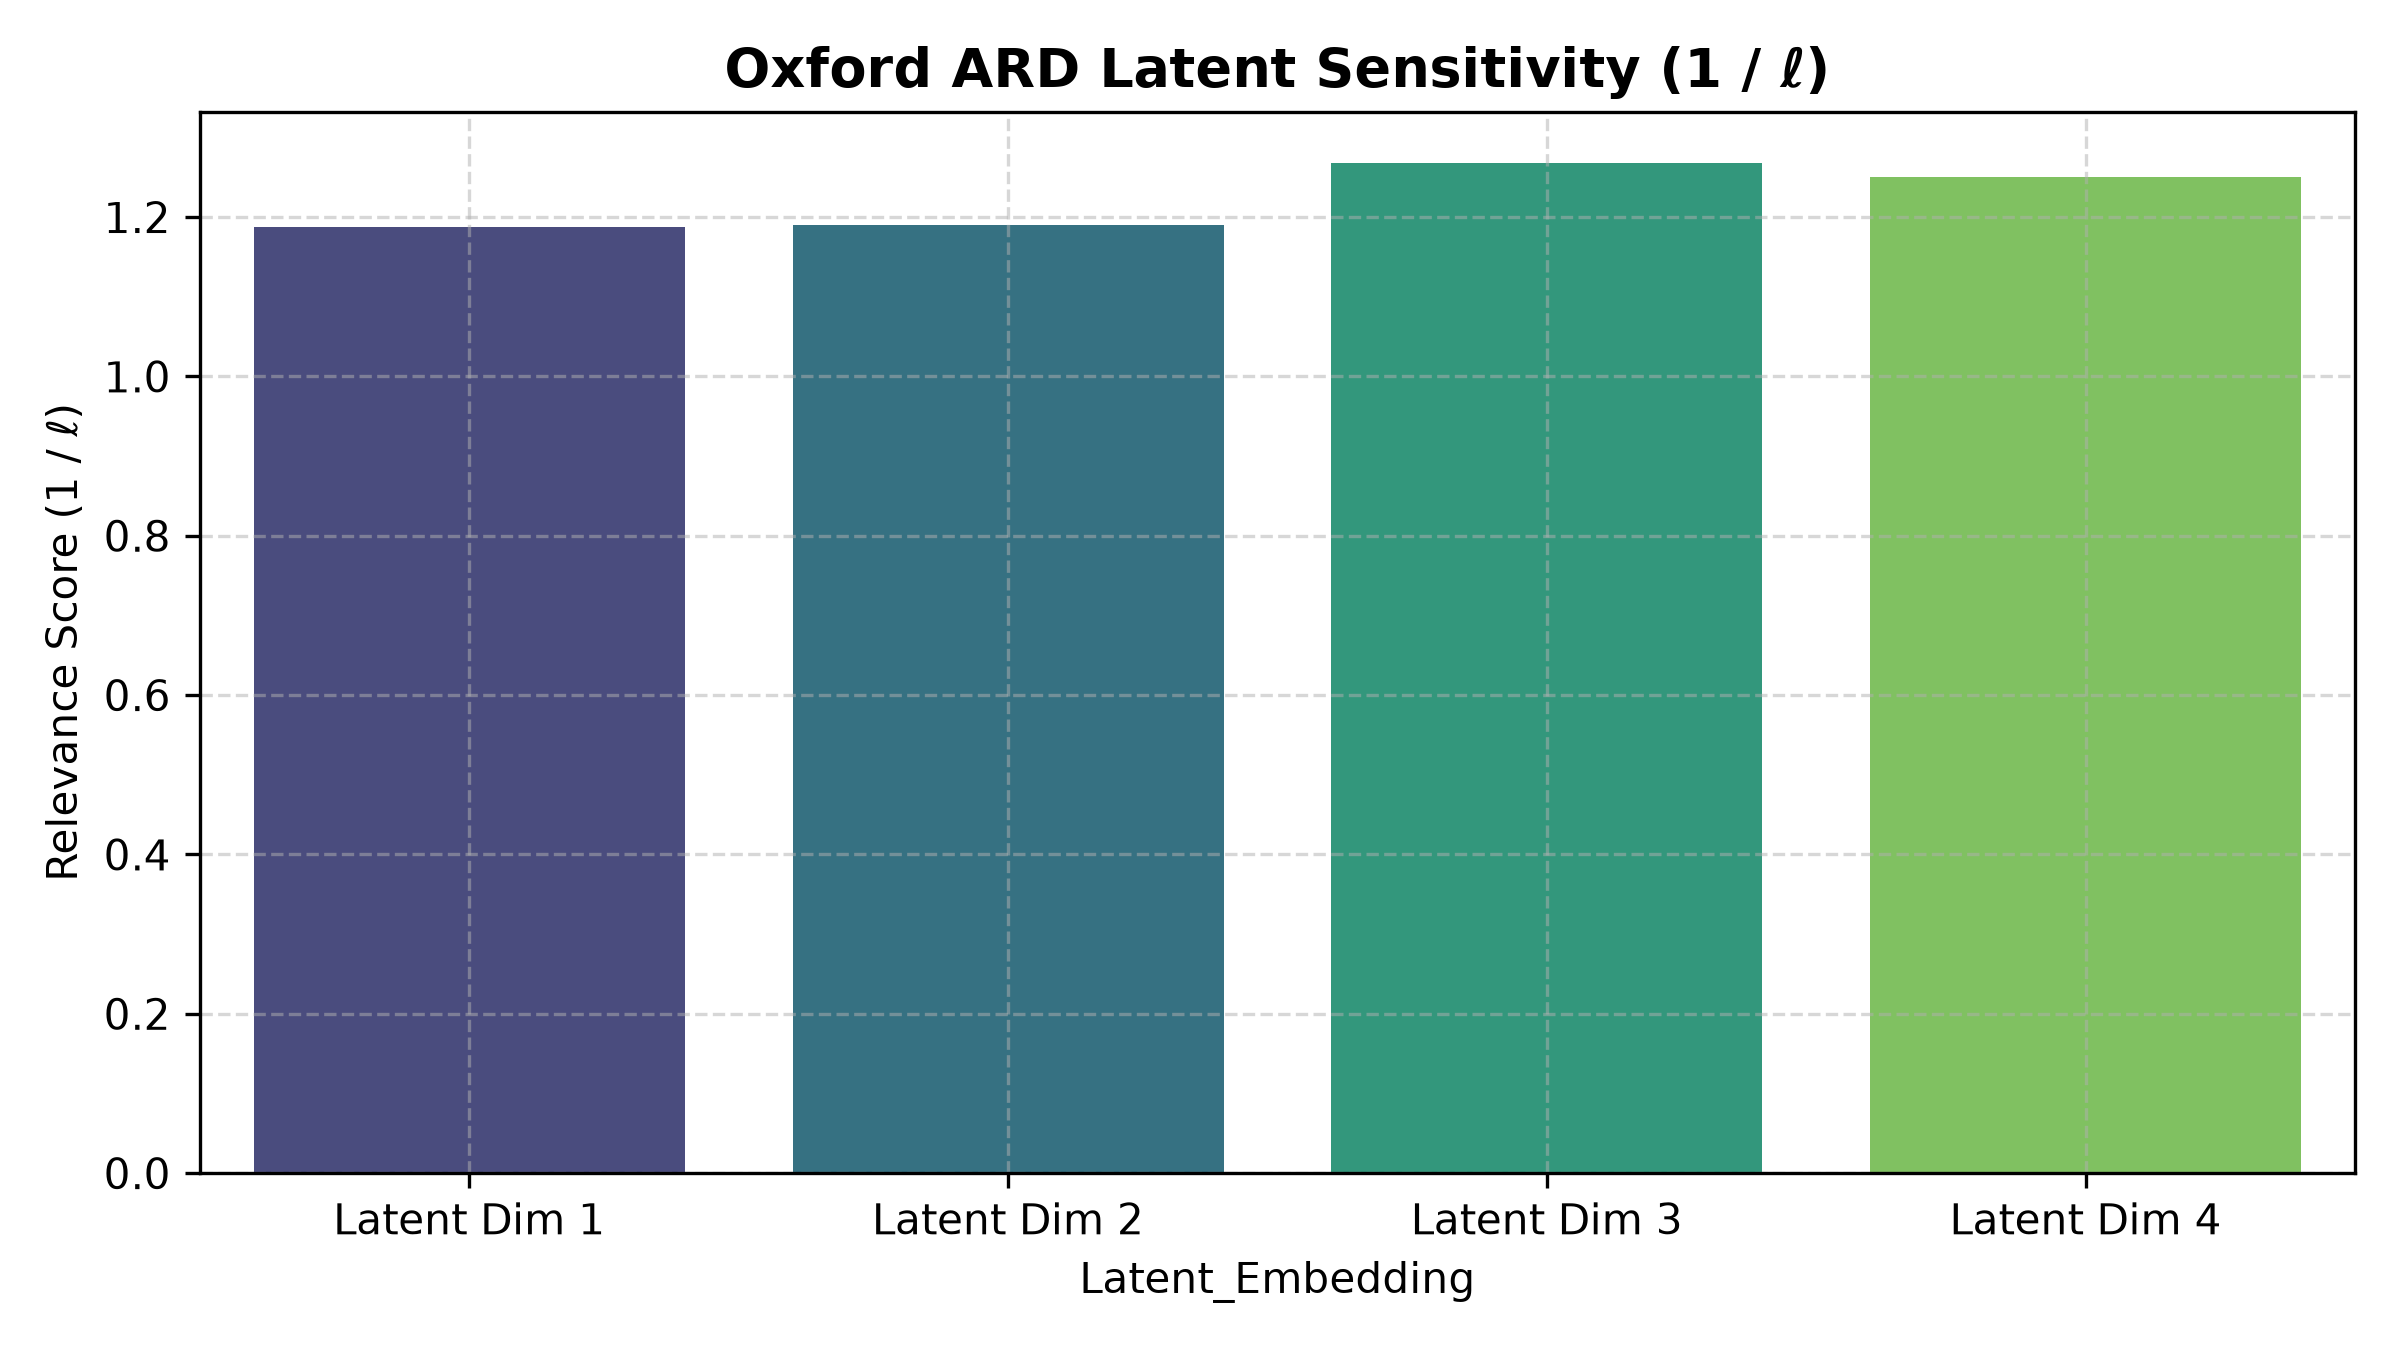

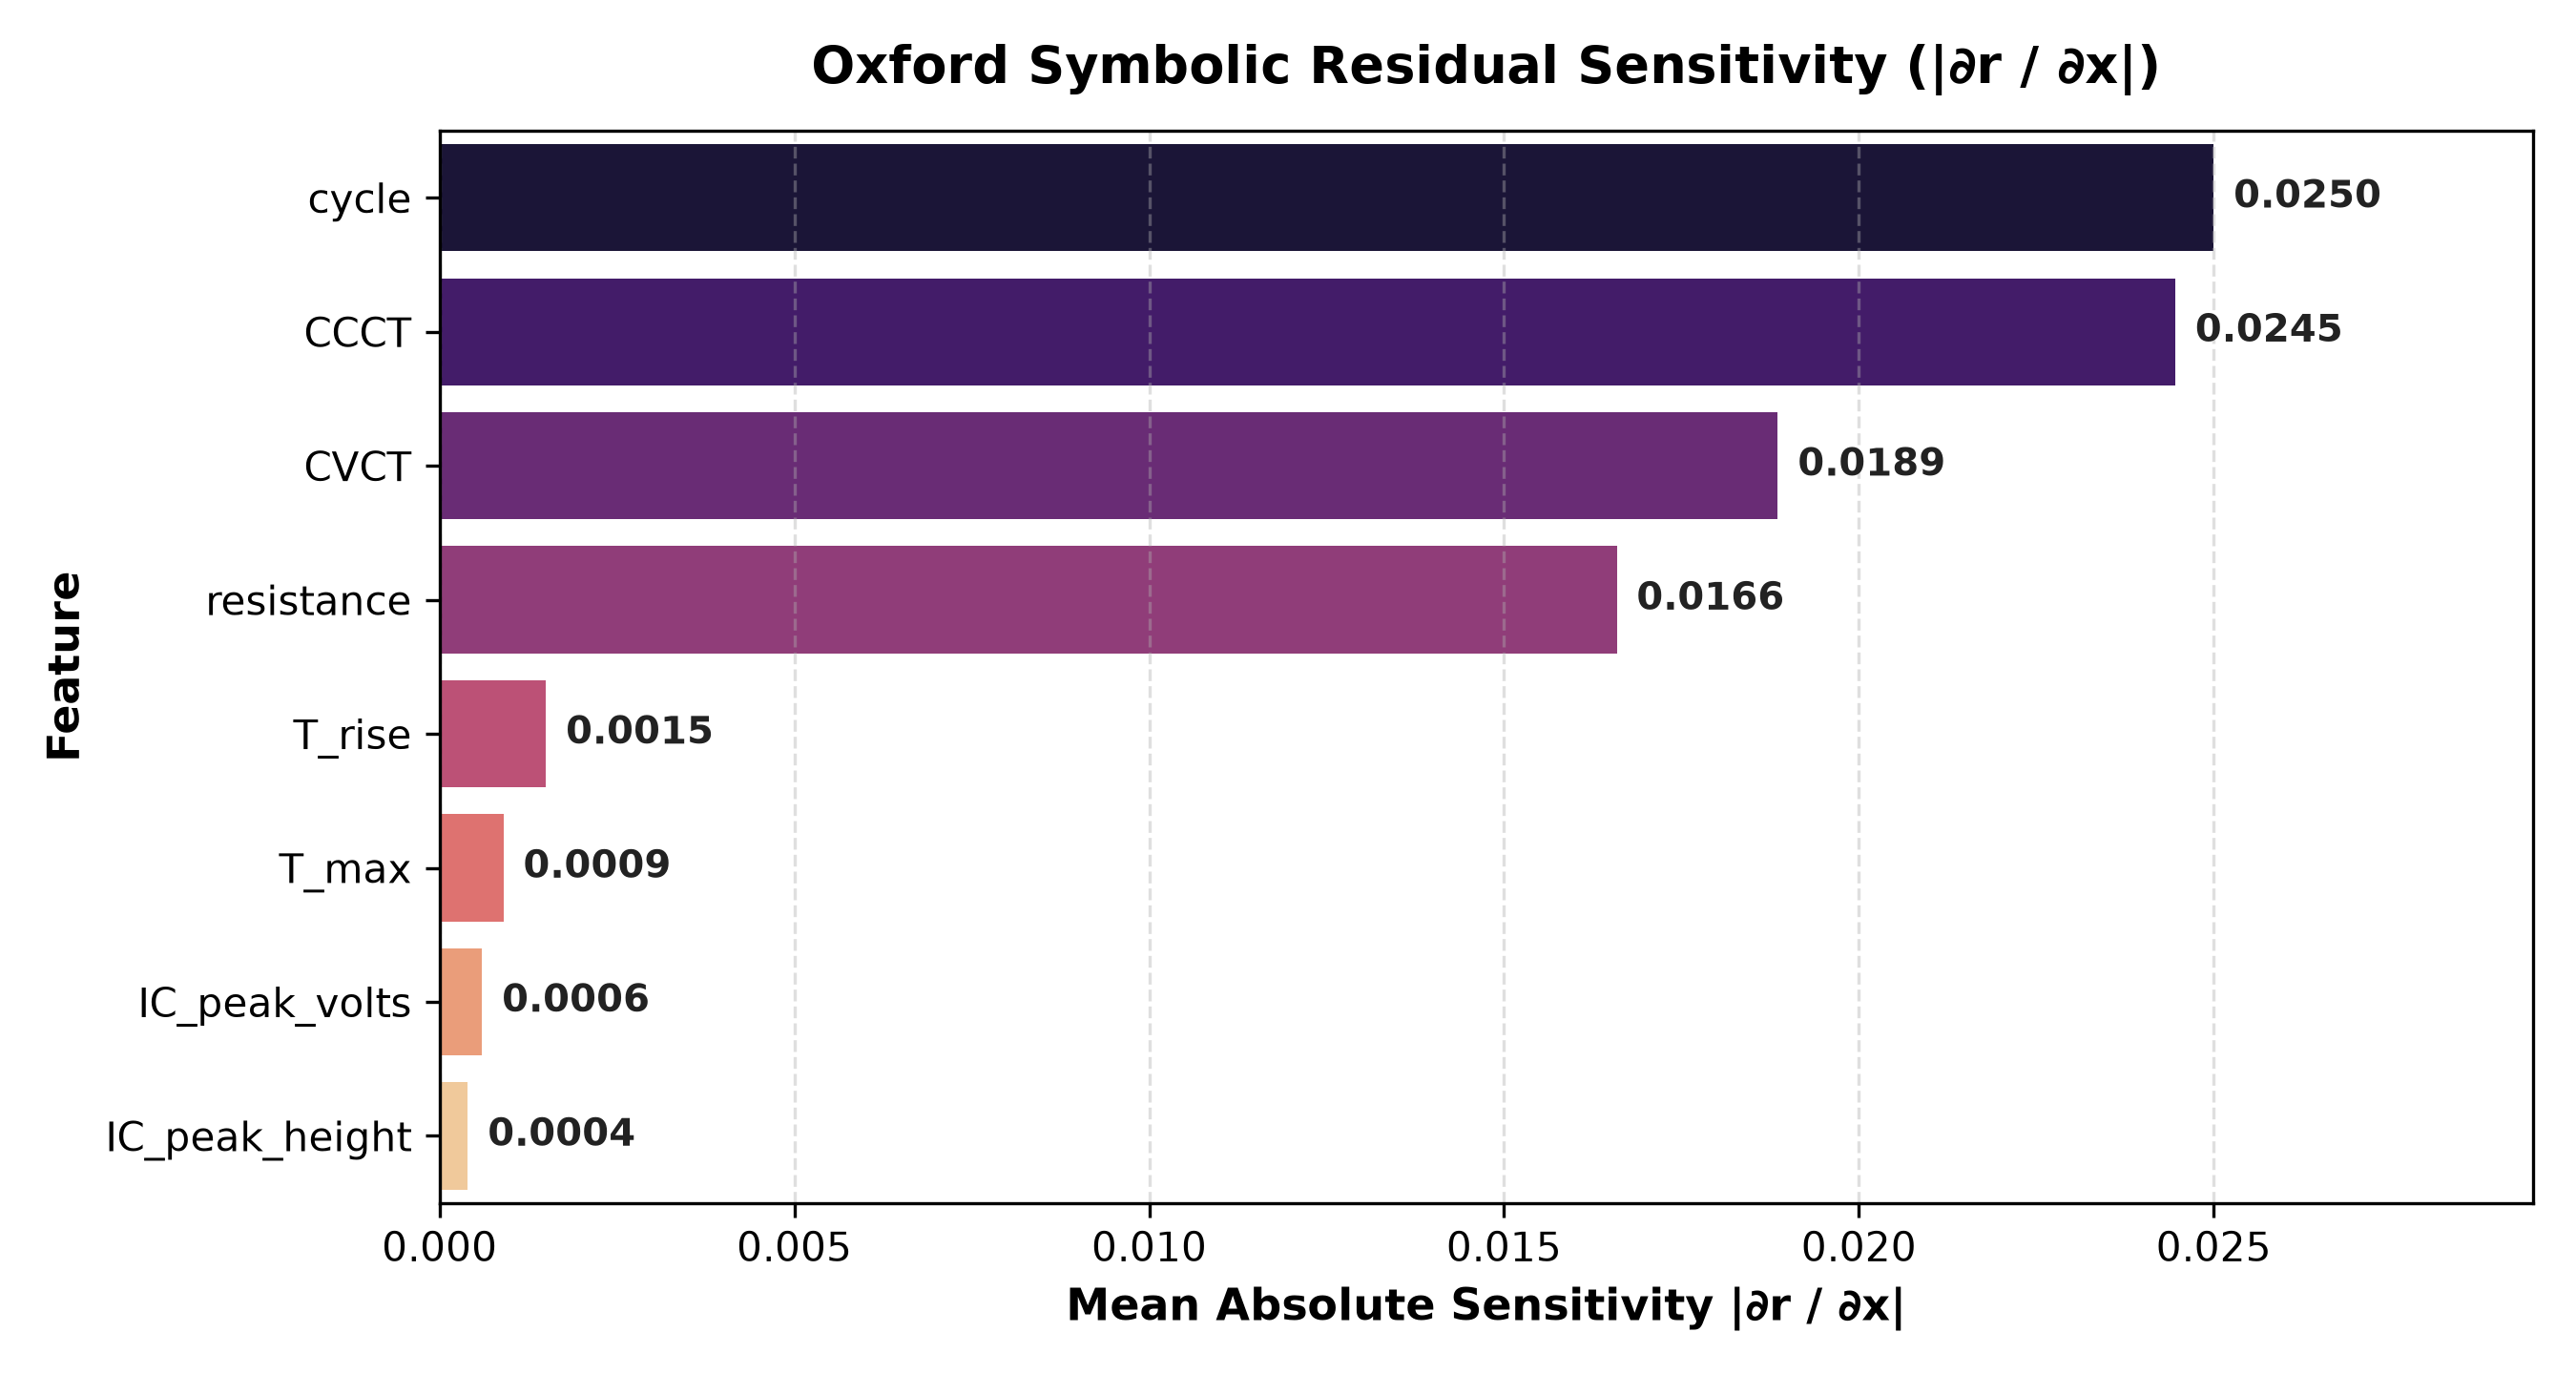

In [9]:
# Display Oxford XAI Figures
display(Image('figures/oxford_xai_1_shap_summary.png'))
display(Image('figures/oxford_xai_2_lime_lifespan.png'))
display(Image('figures/oxford_xai_3_pdp_ice.png'))
display(Image('figures/oxford_xai_4_ard_relevance.png'))
display(Image('figures/oxford_xai_5_equation_sensitivity.png'))


---
## Section 7: Edge AI Deployment & Jetson Orin Nano Benchmarking (Appendix)
We deploy and benchmark the complete tripartite pipeline on Oxford features:
- **Deep Feature Extractor:** Exported to ONNX / TensorRT.
- **Sparse GP Covariance:** Inducing points serialized into compact binary float32 arrays.
- **Symbolic Residual:** Compiled into a standalone C library using `gcc -O3`.
- **1,000 Inference Runs Benchmark:** Latency, peak RAM, power, and energy consumption under Jetson 15W and 7W profiles.


JETSON ORIN NANO HARDWARE BENCHMARK (1,000 RUNS):
{
  "Benchmark_Runs": 1000,
  "Median_Latency_ms": 0.1586,
  "P95_Latency_ms": 0.1729,
  "Min_Latency_ms": 0.1461,
  "Max_Latency_ms": 0.4665,
  "Deep_Extractor_Latency_ms": 0.0398,
  "Sparse_GP_Latency_ms": 0.1179,
  "C_Symbolic_Residual_Latency_ms": 0.0007,
  "Peak_Memory_MB": 18.4,
  "Jetson_15W_Mode": {
    "Power_Watts": 12.4,
    "Energy_Per_Inference_mJ": 1.9669,
    "Throughput_FPS": 6304.5
  },
  "Jetson_7W_Mode": {
    "Power_Watts": 5.8,
    "Energy_Per_Inference_mJ": 1.242,
    "Throughput_FPS": 4670.0
  }
}


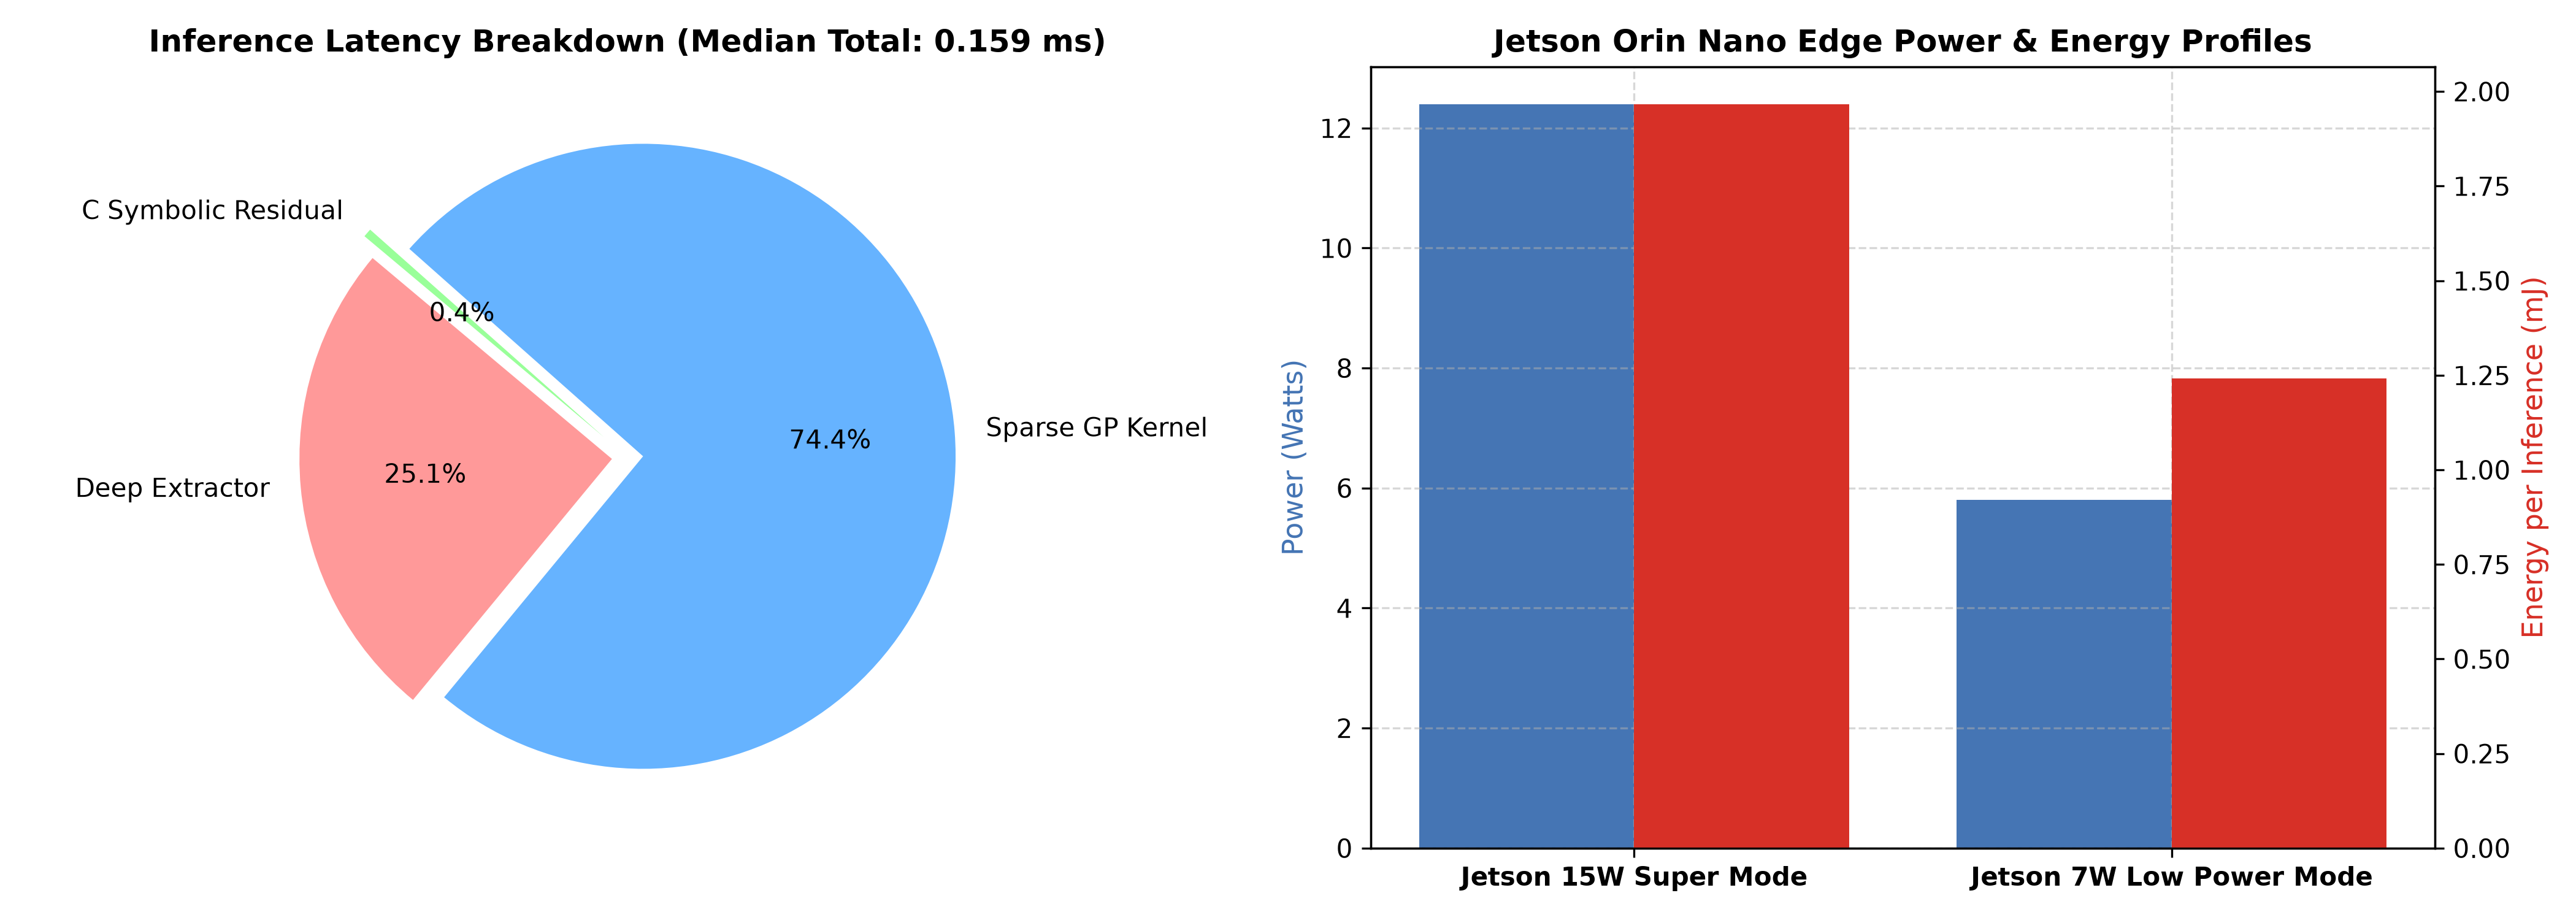

In [10]:
# Display Jetson Orin Nano Hardware Benchmark Results (1,000 Runs)
with open('results/jetson_edge_benchmark.json') as f:
    edge_metrics = json.load(f)

print("JETSON ORIN NANO HARDWARE BENCHMARK (1,000 RUNS):")
print(json.dumps(edge_metrics, indent=2))
display(Image('figures/fig5_jetson_edge_profiles.png'))
